This section holds everything that every later step reads: library imports, the single configuration block, and
the seeding helper. Restart the runtime before a final run so that the determinism flags in the first code cell
take effect before TensorFlow is imported.

### Environment and library imports

In [ ]:
import os
os.environ.setdefault('PYTHONHASHSEED', '42')
os.environ.setdefault('TF_DETERMINISTIC_OPS', '1')
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')

import logging, random, time, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
logging.getLogger('cmdstanpy').setLevel(logging.WARNING)
logging.getLogger('prophet').setLevel(logging.WARNING)
logging.getLogger('tensorflow').setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats
from scipy.stats import skew, kurtosis as scipy_kurtosis
from statsmodels.tsa.stattools import adfuller, acf
from statsmodels.stats.diagnostic import acorr_ljungbox

from prophet import Prophet
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.regularizers import l2

### Protocol configuration (single source of truth)

In [ ]:
SEED = 42

DATA_START      = '2021-01-01'
TRAIN_END       = '2025-12-31'
TEST_START      = '2026-01-01'
TEST_END        = '2026-04-30'
FORECAST_ORIGIN = '2026-04-30'
HORIZON         = 30
MODE_A_START, MODE_A_END, MODE_A_N = '2026-01-31', '2026-04-30', 90
FORECAST_START, FORECAST_END = '2026-05-01', '2026-05-30'

LOOKBACK = 30
LAMBDA   = 0.5

# Level-1 main model: Prophet with seven exogenous regressors
PROPHET_MAIN = dict(growth='linear', n_changepoints=25, changepoint_range=0.8, seasonality_mode='additive',
                    changepoint_prior_scale=0.10, seasonality_prior_scale=5.0,
                    yearly_seasonality=True, weekly_seasonality=True, daily_seasonality=False,
                    interval_width=0.95, mcmc_samples=0, uncertainty_samples=1000)

# Level-2 residual-learning LSTM (univariate: 30-day sequence of Prophet residuals is the sole input)
RESIDUAL_LSTM = dict(units=16, dropout=0.4, l2=0.01, learning_rate=0.001,
                     batch_size=32, max_epochs=80, patience=10, val_fraction=0.10,
                     shuffle=False, loss='mse', optimizer='adam')
RESIDUAL_SCALER_RANGE = (-1, 1)

# Univariate Prophet models used to forecast each exogenous variable (Mode B)
EXOG_PROPHET_COMMON = dict(growth='linear', n_changepoints=25, changepoint_range=0.8, seasonality_mode='additive',
                           seasonality_prior_scale=5.0, yearly_seasonality=True,
                           weekly_seasonality=True, daily_seasonality=False, interval_width=0.80,
                           mcmc_samples=0, uncertainty_samples=1000)

# Stand-alone multivariate LSTM (comparison model only)
STANDALONE_LSTM = dict(max_epochs=80, patience=15, val_fraction=0.10, l2=0.001,
                       tuning_epochs=100, tuning_patience=10)
STANDALONE_CANDIDATES = [
    dict(name='Short window (20)',            window=20, units=32, dropout=0.2, lr=0.001,  batch=16),
    dict(name='Base (30/32/0.3)',             window=30, units=32, dropout=0.3, lr=0.001,  batch=32),
    dict(name='Large units + small LR',       window=30, units=64, dropout=0.3, lr=0.0005, batch=32),
    dict(name='Long window + high dropout',   window=45, units=32, dropout=0.4, lr=0.001,  batch=32),
    dict(name='Small units + small batch',    window=30, units=16, dropout=0.2, lr=0.001,  batch=16),
]
RUN_STANDALONE_TUNING   = True
RUN_PERMUTATION_IMPORTANCE = True
ALPHA_ADF, MAX_DIFF = 0.05, 2

OUTPUT_DIR = Path('outputs'); OUTPUT_DIR.mkdir(exist_ok=True)

# Model labels used consistently in tables, figures and statistical tests
NAME_RW      = 'Random walk'
NAME_PROPHET = 'Prophet (7 exogenous regressors)'
NAME_LSTM    = 'Stand-alone multivariate LSTM (benchmark)'
NAME_HYBRID  = 'Hybrid Prophet-LSTM (residual correction)'

### Reproducibility helpers

In [ ]:
def set_global_seed(seed=SEED):
    """Seed Python, NumPy and TensorFlow. Called immediately before every stochastic step."""
    random.seed(seed); np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)

def compute_metrics(y_true, y_pred, model_name):
    """RMSE, MAE, MAPE, SMAPE and R2 on the IDR/gram scale."""
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    return {'Model': model_name,
            'RMSE (Rp)': float(np.sqrt(mean_squared_error(y_true, y_pred))),
            'MAE (Rp)':  float(mean_absolute_error(y_true, y_pred)),
            'MAPE (%)':  float(np.mean(np.abs((y_true - y_pred) / y_true)) * 100),
            'SMAPE (%)': float(np.mean(2 * np.abs(y_true - y_pred) / (np.abs(y_true) + np.abs(y_pred))) * 100),
            'R²':        float(r2_score(y_true, y_pred))}

def print_metrics(m):
    print(f"  [{m['Model']}]  RMSE=Rp{m['RMSE (Rp)']:,.0f}  MAE=Rp{m['MAE (Rp)']:,.0f}  "
          f"MAPE={m['MAPE (%)']:.4f}%  R²={m['R²']:.6f}")

tf.get_logger().setLevel('ERROR')
set_global_seed()
print('TensorFlow', tf.__version__, '| seed', SEED)

TensorFlow 2.20.0 | seed 42


# Protocol Overview

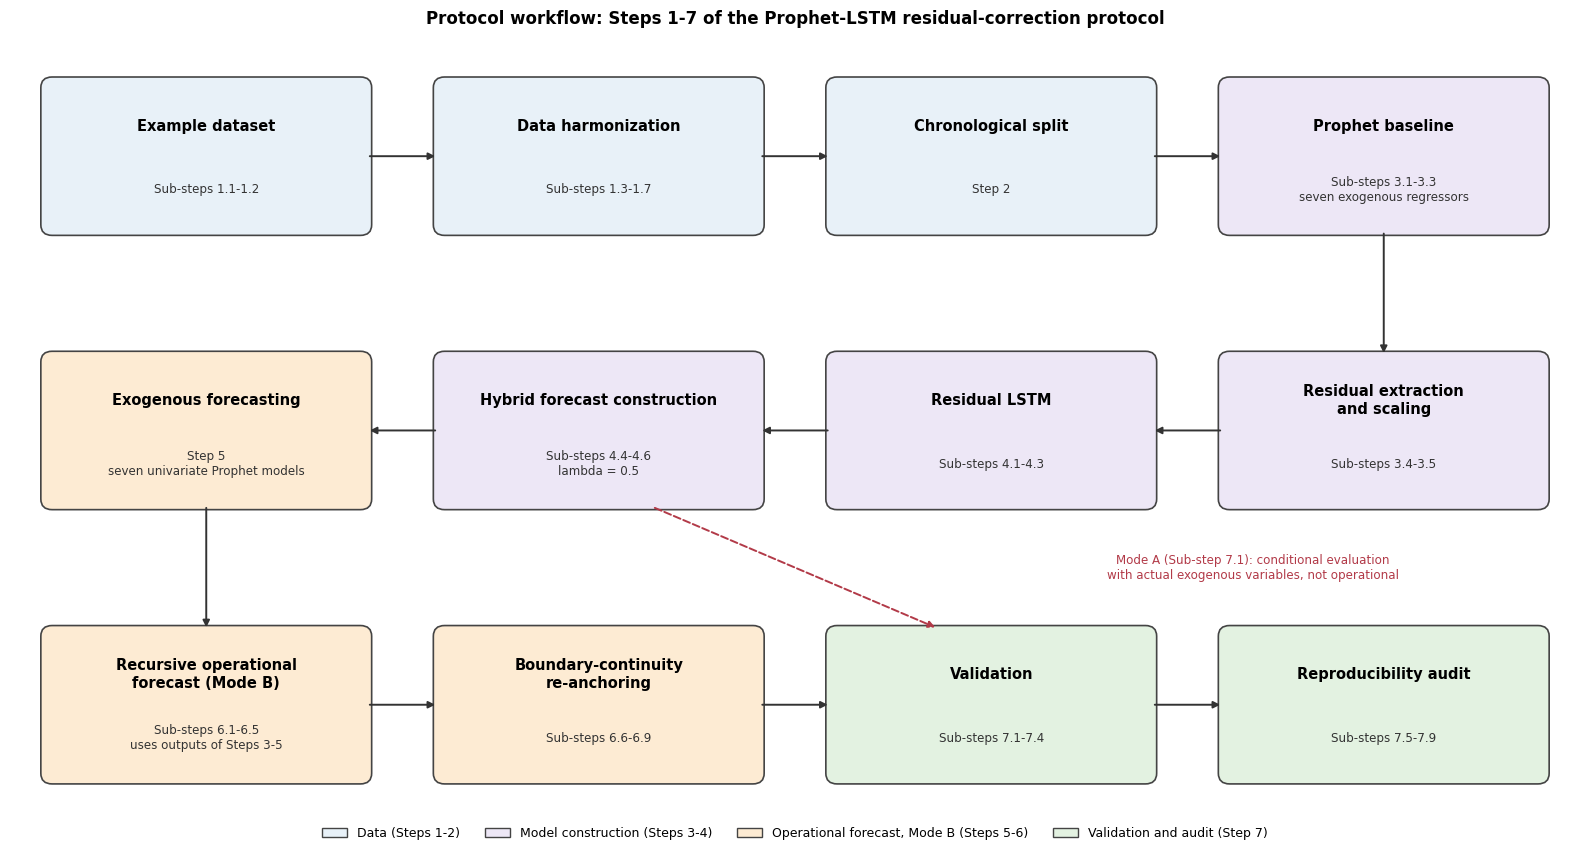

In [ ]:
import matplotlib.patches as mpatches


def draw_protocol_flowchart():
    nodes = [
        ('Example dataset', 'Sub-steps 1.1-1.2', 'data'),
        ('Data harmonization', 'Sub-steps 1.3-1.7', 'data'),
        ('Chronological split', 'Step 2', 'data'),
        ('Prophet baseline', 'Sub-steps 3.1-3.3\nseven exogenous regressors', 'train'),
        ('Residual extraction\nand scaling', 'Sub-steps 3.4-3.5', 'train'),
        ('Residual LSTM', 'Sub-steps 4.1-4.3', 'train'),
        ('Hybrid forecast construction', 'Sub-steps 4.4-4.6\nlambda = 0.5', 'train'),
        ('Exogenous forecasting', 'Step 5\nseven univariate Prophet models', 'modeb'),
        ('Recursive operational\nforecast (Mode B)', 'Sub-steps 6.1-6.5\nuses outputs of Steps 3-5', 'modeb'),
        ('Boundary-continuity\nre-anchoring', 'Sub-steps 6.6-6.9', 'modeb'),
        ('Validation', 'Sub-steps 7.1-7.4', 'valid'),
        ('Reproducibility audit', 'Sub-steps 7.5-7.9', 'valid'),
    ]
    face = {'data': '#E8F1F8', 'train': '#EDE7F6', 'modeb': '#FDEBD3', 'valid': '#E3F2E1'}
    xs, ys = [2.1, 6.3, 10.5, 14.7], [7.2, 4.1, 1.0]
    pos = []
    for i in range(12):
        row, k = divmod(i, 4)
        col = k if row != 1 else 3 - k
        pos.append((xs[col], ys[row]))
    w, h = 3.5, 1.75
    fig, ax = plt.subplots(figsize=(16, 8.6))
    ax.set_xlim(0, 16.8); ax.set_ylim(-0.3, 8.6); ax.axis('off')
    for (x, y), (title, sub, kind) in zip(pos, nodes):
        ax.add_patch(mpatches.FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle='round,pad=0.02,rounding_size=0.12',
                                             fc=face[kind], ec='#444444', lw=1.2))
        ax.text(x, y + 0.34, title, ha='center', va='center', fontsize=10.5, fontweight='bold')
        ax.text(x, y - 0.38, sub, ha='center', va='center', fontsize=8.6, color='#333333')
    arrow = dict(arrowstyle='-|>', color='#333333', lw=1.4, shrinkA=0, shrinkB=0)
    for i in range(11):
        (x1, y1), (x2, y2) = pos[i], pos[i + 1]
        if abs(y1 - y2) < 1e-9:
            sign = 1 if x2 > x1 else -1
            ax.annotate('', xy=(x2 - sign * w / 2, y2), xytext=(x1 + sign * w / 2, y1), arrowprops=arrow)
        else:
            ax.annotate('', xy=(x2, y2 + h / 2), xytext=(x1, y1 - h / 2), arrowprops=arrow)

    # Mode A: evaluation only, branches from the hybrid construction to the validation node
    (xa, ya), (xb, yb) = pos[6], pos[10]
    ax.annotate('', xy=(xb - 0.6, yb + h / 2), xytext=(xa + 0.6, ya - h / 2),
                arrowprops=dict(arrowstyle='-|>', color='#B23A48', lw=1.4, ls='--', shrinkA=0, shrinkB=0))
    ax.text(13.3, 2.55, 'Mode A (Sub-step 7.1): conditional evaluation\nwith actual exogenous variables, not operational',
            ha='center', va='center', fontsize=8.6, color='#B23A48')
    ax.set_title('Protocol workflow: Steps 1-7 of the Prophet-LSTM residual-correction protocol', fontweight='bold', fontsize=12)
    handles = [mpatches.Patch(fc=face[k], ec='#444444', label=l) for k, l in
               [('data', 'Data (Steps 1-2)'), ('train', 'Model construction (Steps 3-4)'),
                ('modeb', 'Operational forecast, Mode B (Steps 5-6)'), ('valid', 'Validation and audit (Step 7)')]]
    ax.legend(handles=handles, loc='lower center', ncol=4, frameon=False, fontsize=9, bbox_to_anchor=(0.5, -0.04))
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'fig_protocol_workflow.png', dpi=150, bbox_inches='tight')
    plt.show()


draw_protocol_flowchart()

# **Step 1: Example Dataset and Data Harmonization**


## **Sub-step 1.1: Load the Example Dataset**


In [ ]:
def parse_gau_idr(filepath):
    """Parse GAU_IDR.csv (dd/mm/yyyy dates, Indonesian number format)."""
    with open(filepath, 'r', encoding='utf-8-sig') as f:
        lines = f.readlines()
    rows = []
    for line in lines[1:]:
        line = line.strip().strip('"')
        parts = [p.strip('"') for p in line.split(',')]
        if len(parts) >= 2:
            val_part = parts[1].replace('.', '').replace(',', '.')
            try:
                rows.append({'Tanggal': parts[0], 'GAU_IDR': float(val_part)})
            except ValueError:
                pass
    df = pd.DataFrame(rows)
    if 'Tanggal' in df.columns:
        df['Tanggal'] = pd.to_datetime(df['Tanggal'], format='%d/%m/%Y', errors='coerce')
        return df.dropna(subset=['Tanggal']).sort_values('Tanggal').reset_index(drop=True)
    return pd.DataFrame()

In [ ]:
def locate_data_dir():
    """Colab: Google Drive folder of the original project. Local: ./data or $METHODSX_DATA_DIR."""
    try:
        from google.colab import drive
        in_colab = True
    except ImportError:
        in_colab = False
    if in_colab:
        if not Path('/content/drive/MyDrive').exists():
            drive.mount('/content/drive')
        default_dir = Path('/content/drive/MyDrive/TUGAS AKHIR YG INI/DATA')
    else:
        default_dir = Path.cwd() / 'data'
    return Path(os.environ.get('METHODSX_DATA_DIR', str(default_dir))).expanduser()

def load_example_dataset(data_dir):
    """Load the eight raw source files after verifying that all of them exist."""
    required = ['GAU_IDR.csv', 'GAU_USD.csv', 'DXY.csv', 'FED Rate.csv', 'harga minyak dunia.csv',
                'USD_IDR Historical Data.csv', 'Data Inflasi.xlsx', 'BI Rate.xlsx']
    missing = [f for f in required if not (data_dir / f).is_file()]
    if missing:
        raise FileNotFoundError(
            f'Missing input files in {data_dir.resolve()}:\n' + '\n'.join(f'  - {f}' for f in missing) +
            '\nSet METHODSX_DATA_DIR or place the files in ./data, then rerun.')
    return {
        'GAU_IDR' : parse_gau_idr(data_dir / 'GAU_IDR.csv'),
        'GAU_USD' : pd.read_csv(data_dir / 'GAU_USD.csv'),
        'DXY'     : pd.read_csv(data_dir / 'DXY.csv'),
        'FED'     : pd.read_csv(data_dir / 'FED Rate.csv'),
        'Oil'     : pd.read_csv(data_dir / 'harga minyak dunia.csv', sep=',', encoding='utf-8-sig'),
        'USD_IDR' : pd.read_csv(data_dir / 'USD_IDR Historical Data.csv'),
        'Inflation': pd.read_excel(data_dir / 'Data Inflasi.xlsx', header=3),
        'BI'      : pd.read_excel(data_dir / 'BI Rate.xlsx'),
    }

In [ ]:
DATA_DIR = locate_data_dir()
print(f'Data directory: {DATA_DIR.resolve()}')
raw = load_example_dataset(DATA_DIR)
for name, frame in raw.items():
    print(f'  {name:10s}: {frame.shape}')

Data directory: /content/drive/MyDrive/TUGAS AKHIR YG INI/DATA
  GAU_IDR   : (1567, 2)
  GAU_USD   : (1385, 7)
  DXY       : (1381, 7)
  FED       : (64, 2)
  Oil       : (1376, 7)
  USD_IDR   : (1355, 7)
  Inflation : (65, 4)
  BI        : (68, 4)


## **Sub-step 1.2: Define the Target and Seven Exogenous Variables**


In [ ]:
TARGET_SPEC = dict(name='GAU_IDR', model_name='log_GAU_IDR', label='GAU/IDR', unit='IDR/gram', log=True)

EXOG_SPEC = [
    dict(code='X1', name='GAU_USD',   model_name='log_GAU_USD',   label='GAU/USD',               unit='USD/gram', freq='daily',   log=True,  cps=0.20),
    dict(code='X2', name='DXY',       model_name='DXY',           label='US Dollar Index (DXY)', unit='index',    freq='daily',   log=False, cps=0.20),
    dict(code='X3', name='FED_Rate',  model_name='FED_Rate',      label='Federal Funds Rate',    unit='%',        freq='monthly', log=False, cps=0.03),
    dict(code='X4', name='BI_Rate',   model_name='BI_Rate',       label='BI Rate',               unit='%',        freq='monthly', log=False, cps=0.03),
    dict(code='X5', name='Inflation', model_name='Inflation',     label='Indonesian inflation',  unit='%',        freq='monthly', log=False, cps=0.03),
    dict(code='X6', name='Oil',       model_name='log_Oil', label='Crude oil', unit='USD/barrel', freq='daily', log=True, cps=0.20),
    dict(code='X7', name='USD_IDR',   model_name='log_USD_IDR',   label='USD/IDR',               unit='IDR/USD',  freq='daily',   log=True,  cps=0.20),
]
TARGET        = TARGET_SPEC['model_name']
FEATURES      = [s['model_name'] for s in EXOG_SPEC]
EXOG_NATURAL  = [s['name'] for s in EXOG_SPEC]
FUTURE_EXOG_COLUMNS = ['GAU_USD', 'USD_IDR', 'DXY', 'FED_Rate', 'BI_Rate', 'Oil', 'Inflation']
assert len(FEATURES) == 7 and len(set(FEATURES)) == 7 and set(EXOG_NATURAL) == set(FUTURE_EXOG_COLUMNS)

display(pd.DataFrame(EXOG_SPEC)[['code', 'name', 'model_name', 'label', 'unit', 'freq', 'log', 'cps']]
        .rename(columns={'name': 'column (natural units)', 'model_name': 'Prophet regressor',
                         'log': 'log-transformed', 'cps': 'changepoint prior (Mode B)'}))

,code,column (natural units),Prophet regressor,label,unit,freq,log-transformed,changepoint prior (Mode B)
0,X1,GAU_USD,log_GAU_USD,GAU/USD,USD/gram,daily,True,0.20
1,X2,DXY,DXY,US Dollar Index (DXY),index,daily,False,0.20
2,X3,FED_Rate,FED_Rate,Federal Funds Rate,%,monthly,False,0.03
3,X4,BI_Rate,BI_Rate,BI Rate,%,monthly,False,0.03
4,X5,Inflation,Inflation,Indonesian inflation,%,monthly,False,0.03
5,X6,Oil,log_Oil,Crude oil,USD/barrel,daily,True,0.20
6,X7,USD_IDR,log_USD_IDR,USD/IDR,IDR/USD,daily,True,0.20


## **Sub-step 1.3: Standardize Date Formats**


In [ ]:
BI_RATE_TABLE = [
    ('2021-01-01', 3.75), ('2021-02-01', 3.5), ('2021-03-01', 3.5), ('2021-04-01', 3.5),
    ('2021-05-01', 3.5), ('2021-06-01', 3.5), ('2021-07-01', 3.5), ('2021-08-01', 3.5),
    ('2021-09-01', 3.5), ('2021-10-01', 3.5), ('2021-11-01', 3.5), ('2021-12-01', 3.5),
    ('2022-01-01', 3.5), ('2022-02-01', 3.5), ('2022-03-01', 3.5), ('2022-04-01', 3.5),
    ('2022-05-01', 3.5), ('2022-06-01', 3.5), ('2022-07-01', 3.5), ('2022-08-01', 3.75),
    ('2022-09-01', 4.25), ('2022-10-01', 4.75), ('2022-11-01', 5.25), ('2022-12-01', 5.5),
    ('2023-01-01', 5.75), ('2023-02-01', 5.75), ('2023-03-01', 5.75), ('2023-04-01', 5.75),
    ('2023-05-01', 5.75), ('2023-06-01', 5.75), ('2023-07-01', 5.75), ('2023-08-01', 5.75),
    ('2023-09-01', 5.75), ('2023-10-01', 6.0), ('2023-11-01', 6.0), ('2023-12-01', 6.0),
    ('2024-01-01', 6.0), ('2024-02-01', 6.0), ('2024-03-01', 6.0), ('2024-04-01', 6.25),
    ('2024-05-01', 6.25), ('2024-06-01', 6.25), ('2024-07-01', 6.25), ('2024-08-01', 6.25),
    ('2024-09-01', 6.0), ('2024-10-01', 6.0), ('2024-11-01', 6.0), ('2024-12-01', 6.0),
    ('2025-01-01', 5.75), ('2025-02-01', 5.75), ('2025-03-01', 5.75), ('2025-04-01', 5.75),
    ('2025-05-01', 5.75), ('2025-06-01', 5.75), ('2025-07-01', 5.75), ('2025-08-01', 5.75),
    ('2025-09-01', 5.75), ('2025-10-01', 5.75), ('2025-11-01', 5.75), ('2025-12-01', 5.75),
    ('2026-01-01', 4.75), ('2026-02-01', 4.75), ('2026-03-01', 4.75), ('2026-04-01', 4.75),
]

BULAN_MAP = {'Januari': '01', 'Februari': '02', 'Maret': '03', 'April': '04', 'Mei': '05', 'Juni': '06',
             'Juli': '07', 'Agustus': '08', 'September': '09', 'Oktober': '10', 'November': '11', 'Desember': '12'}

def _finalize(df, col):
    df = df.dropna(subset=['Date']).set_index('Date').sort_index()
    df = df[~df.index.duplicated(keep='last')]
    return df[col]

def parse_raw_variables(raw):
    """Return a dict of date-indexed pandas Series, one per variable (target + seven exogenous)."""
    out = {}

    d = raw['GAU_IDR'].copy(); d.columns = ['Date', 'GAU_IDR']
    d['Date'] = pd.to_datetime(d['Date'], errors='coerce')
    d = d.dropna(subset=['Date']); d = d[d['Date'] >= DATA_START]
    d['GAU_IDR'] = pd.to_numeric(d['GAU_IDR'], errors='coerce')
    out['GAU_IDR'] = _finalize(d, 'GAU_IDR')

    d = raw['GAU_USD'].copy()
    dc = d.columns[0]
    vc = next((c for c in d.columns if any(k in c.lower() for k in ['terakhir', 'price', 'gau', 'close'])), d.columns[1])
    d = d[[dc, vc]].rename(columns={dc: 'Date', vc: 'GAU_USD'})
    d['Date'] = pd.to_datetime(d['Date'], dayfirst=True, errors='coerce')
    d['GAU_USD'] = pd.to_numeric(d['GAU_USD'].astype(str).str.replace('.', '', regex=False).str.replace(',', '.', regex=False), errors='coerce')
    out['GAU_USD'] = _finalize(d, 'GAU_USD')

    d = raw['DXY'].copy(); d.columns = d.columns.str.strip()
    vc = next((c for c in d.columns if any(k in c.lower() for k in ['dxy', 'close'])), d.columns[1])
    dc = d.columns[0]
    d = d[[dc, vc]].rename(columns={dc: 'Date', vc: 'DXY'})
    d['Date'] = pd.to_datetime(d['Date'], errors='coerce'); d['DXY'] = pd.to_numeric(d['DXY'], errors='coerce')
    out['DXY'] = _finalize(d, 'DXY')

    d = raw['FED'].copy()
    if 'FED_Rate' not in d.columns:
        d.columns = ['Date', 'FED_Rate']
    d['Date'] = pd.to_datetime(d['Date'], errors='coerce')
    d['FED_Rate'] = pd.to_numeric(d['FED_Rate'].astype(str).str.replace(',', '.').str.replace('%', ''), errors='coerce')
    out['FED_Rate'] = _finalize(d, 'FED_Rate')

    d = pd.DataFrame(BI_RATE_TABLE, columns=['Date', 'BI_Rate']); d['Date'] = pd.to_datetime(d['Date'])
    out['BI_Rate'] = d.set_index('Date').sort_index()['BI_Rate']

    d = raw['Inflation'].copy().iloc[1:].copy()
    d.columns = ['No', 'Periode', 'Inflation', 'Dummy']
    d = d[['Periode', 'Inflation']].copy()
    d['Inflation'] = pd.to_numeric(d['Inflation'].astype(str).str.replace('%', '').str.strip(), errors='coerce')
    def parse_period(x):
        try:
            bulan, tahun = str(x).split()
            return pd.to_datetime(f"{tahun}-{BULAN_MAP.get(bulan, '01')}-01")
        except Exception:
            return pd.NaT
    d['Date'] = d['Periode'].apply(parse_period)
    d = d.dropna().set_index('Date')[['Inflation']].sort_index()
    out['Inflation'] = d[~d.index.duplicated(keep='last')]['Inflation']

    d = raw['Oil'].copy(); d.columns = d.columns.str.strip()
    vc = next((c for c in d.columns if any(k in c.lower() for k in ['oil', 'minyak', 'price', 'close'])), d.columns[1])
    dc = d.columns[0]
    d = d[[dc, vc]].rename(columns={dc: 'Date', vc: 'Oil'})
    d['Date'] = pd.to_datetime(d['Date'], errors='coerce')
    d['Oil'] = pd.to_numeric(d['Oil'].astype(str).str.replace(',', '.'), errors='coerce')
    out['Oil'] = _finalize(d, 'Oil')

    d = raw['USD_IDR'].copy(); d.columns = d.columns.str.strip()
    vc = next((c for c in d.columns if any(k in c.lower() for k in ['usd', 'idr', 'kurs', 'rate', 'close', 'terakhir'])), d.columns[1])
    dc = d.columns[0]
    d = d[[dc, vc]].rename(columns={dc: 'Date', vc: 'USD_IDR'})
    d['Date'] = pd.to_datetime(d['Date'], dayfirst=True, errors='coerce')
    d['USD_IDR'] = pd.to_numeric(d['USD_IDR'].astype(str).str.replace(',', '', regex=False), errors='coerce')
    out['USD_IDR'] = _finalize(d, 'USD_IDR')
    return out

series_raw = parse_raw_variables(raw)
print('Parsed series:', ', '.join(series_raw))

Parsed series: GAU_IDR, GAU_USD, DXY, FED_Rate, BI_Rate, Inflation, Oil, USD_IDR


## **Sub-step 1.4: Construct the Daily Calendar**


In [ ]:
VARIABLE_ORDER   = ['GAU_IDR', 'GAU_USD', 'DXY', 'FED_Rate', 'BI_Rate', 'Inflation', 'Oil', 'USD_IDR']
DAILY_BACKFILL   = ['GAU_IDR', 'GAU_USD', 'DXY', 'Oil', 'USD_IDR']   # as in the source implementation

def harmonize_daily_data(series_dict, start=DATA_START, end=FORECAST_ORIGIN):
    """Join the eight series on a daily calendar. Returns (dataframe, fill_report)."""
    calendar = pd.date_range(start=start, end=end, freq='D', name='Date')
    df = pd.DataFrame(index=calendar)
    for name in VARIABLE_ORDER:
        df = df.join(series_dict[name].rename(name))
    df = df.ffill()
    report = {'backfilled_before_first_observation': df[DAILY_BACKFILL].isna().sum().to_dict()}
    df[DAILY_BACKFILL] = df[DAILY_BACKFILL].bfill()
    df = df[~df.index.duplicated(keep='last')]
    df = df.apply(pd.to_numeric, errors='coerce').ffill()
    report['remaining_missing'] = int(df.isna().sum().sum())
    return df, report

df_all, fill_report = harmonize_daily_data(series_raw)
print(f'Daily frame (target + 7 exogenous variables): {df_all.shape} | {df_all.index.min().date()} -> {df_all.index.max().date()}')
display(df_all.head(3)); display(df_all.tail(3))

Daily frame (target + 7 exogenous variables): (1946, 8) | 2021-01-01 -> 2026-04-30


,GAU_IDR,GAU_USD,DXY,FED_Rate,BI_Rate,Inflation,Oil,USD_IDR
Date,,,,,,,,
2021-01-01,867623.0,61.025,89.94,0.09,3.75,1.55,51.09,14213.7
2021-01-02,867623.0,61.025,89.94,0.09,3.75,1.55,51.09,14010.0
2021-01-03,874168.0,61.025,89.94,0.09,3.75,1.55,51.09,14250.0


,GAU_IDR,GAU_USD,DXY,FED_Rate,BI_Rate,Inflation,Oil,USD_IDR
Date,,,,,,,,
2026-04-28,2543628.0,147.749,98.64,3.64,4.75,2.42,111.26,16885.0
2026-04-29,2533023.0,146.097,98.96,3.64,4.75,2.42,118.03,16885.0
2026-04-30,2573810.0,148.620,98.06,3.64,4.75,2.42,114.01,16885.0


## **Sub-step 1.5: Align Daily and Monthly Variables**


In [ ]:
rows = []
for spec in [TARGET_SPEC] + EXOG_SPEC:
    s = series_raw[spec['name']].loc[DATA_START:FORECAST_ORIGIN].dropna()
    rows.append({'Variable': spec['label'], 'Column': spec['name'], 'Native frequency': spec.get('freq', 'daily'),
                 'Native observations': len(s), 'First native date': s.index.min().date(),
                 'Last native date': s.index.max().date(),
                 'Daily rows after harmonization': int(df_all[spec['name']].notna().sum())})
display(pd.DataFrame(rows))

,Variable,Column,Native frequency,Native observations,First native date,Last native date,Daily rows after harmonization
0,GAU/IDR,GAU_IDR,daily,1566,2021-01-01,2026-04-30,1946
1,GAU/USD,GAU_USD,daily,1384,2021-01-01,2026-04-30,1946
2,US Dollar Index (DXY),DXY,daily,1380,2021-01-01,2026-04-30,1946
3,Federal Funds Rate,FED_Rate,monthly,64,2021-01-01,2026-04-01,1946
4,BI Rate,BI_Rate,monthly,64,2021-01-01,2026-04-01,1946
5,Indonesian inflation,Inflation,monthly,64,2021-01-01,2026-04-01,1946
6,Crude oil,Oil,daily,1375,2021-01-04,2026-04-30,1946
7,USD/IDR,USD_IDR,daily,511,2021-01-01,2026-04-03,1946


## **Sub-step 1.6: Handle Missing Values**


In [ ]:
print('Values filled by backward-fill (dates before the first observation of each daily series):')
display(pd.Series(fill_report['backfilled_before_first_observation'], name='n_values').to_frame())
print('Missing values remaining after harmonization:', fill_report['remaining_missing'])
assert fill_report['remaining_missing'] == 0, 'Missing values remain after harmonization.'

Values filled by backward-fill (dates before the first observation of each daily series):


,n_values
GAU_IDR,0
GAU_USD,0
DXY,0
Oil,3
USD_IDR,0


Missing values remaining after harmonization: 0


### Sub-step 1.7: Validate the Harmonized Dataset


In [ ]:
# Table 1. Dataset validation and magnitude check

EXPECTED_RANGE = {
    'GAU_IDR': (800_000, 3_500_000),
    'GAU_USD': (50, 200),
    'DXY': (90, 115),
    'FED_Rate': (0.0, 5.5),
    'BI_Rate': (3.0, 7.0),
    'Inflation': (-2.0, 10.0),
    'Oil': (50, 150),
    'USD_IDR': (13_000, 17_000),
}


def validate_daily_dataset(df, start=DATA_START, end=FORECAST_ORIGIN):

    expected_rows = (pd.Timestamp(end) - pd.Timestamp(start)).days + 1

    hard = [
        (
            'Complete daily calendar',
            len(df) == expected_rows,
            f'{len(df)} rows, expected {expected_rows}',
        ),
        ('Unique dates', bool(df.index.is_unique), ''),
        (
            'No missing values',
            int(df.isna().sum().sum()) == 0,
            f'{int(df.isna().sum().sum())} NaN',
        ),
        (
            'All eight variables present',
            set(df.columns) == set(VARIABLE_ORDER),
            ', '.join(df.columns),
        ),
        (
            'Calendar ends at forecast origin',
            df.index.max() == pd.Timestamp(FORECAST_ORIGIN),
            str(df.index.max().date()),
        ),
        (
            'Calendar starts at DATA_START',
            df.index.min() == pd.Timestamp(start),
            str(df.index.min().date()),
        ),
        ('Chronological order', bool(df.index.is_monotonic_increasing), ''),
        (
            'All columns numeric',
            all(pd.api.types.is_numeric_dtype(t) for t in df.dtypes),
            '',
        ),
    ]

    structural_report = pd.DataFrame(hard, columns=['check', 'passed', 'detail'])

    if not structural_report['passed'].all():
        display(structural_report)
        raise AssertionError('Daily dataset validation failed.')

    soft = []

    for col, (lo, hi) in EXPECTED_RANGE.items():

        v = float(df[col].iloc[-30:].mean())

        soft.append({
            'variable': col,
            'mean_last_30d': v,
            'expected_low': lo,
            'expected_high': hi,
            'within_range': lo <= v <= hi,
        })

    magnitude_report = pd.DataFrame(soft)

    return structural_report, magnitude_report


structural_report, magnitude_report = validate_daily_dataset(df_all)


# Combine structural validation and magnitude check
table1_validation = pd.concat(
    [
        structural_report.assign(category='Structural validation')
        .rename(columns={'check': 'variable', 'detail': 'value'})[
            ['category', 'variable', 'passed', 'value']
        ],
        magnitude_report.assign(category='Magnitude check').rename(
            columns={'within_range': 'passed'}
        )[['category', 'variable', 'passed']],
    ],
    ignore_index=True,
)


display(table1_validation)

,category,variable,passed,value
0,Structural validation,Complete daily calendar,True,"1946 rows, expected 1946"
1,Structural validation,Unique dates,True,
2,Structural validation,No missing values,True,0 NaN
3,Structural validation,All eight variables present,True,"GAU_IDR, GAU_USD, DXY, FED_Rate, BI_Rate, Infl..."
4,Structural validation,Calendar ends at forecast origin,True,2026-04-30
5,Structural validation,Calendar starts at DATA_START,True,2021-01-01
6,Structural validation,Chronological order,True,
7,Structural validation,All columns numeric,True,
8,Magnitude check,GAU_IDR,True,NaN
9,Magnitude check,GAU_USD,True,NaN


### **Supporting descriptive statistics and series overview**

,Unit,count,mean,median,std,min,max,Skewness,Kurtosis
GAU_IDR,IDR/gram,1946,"1,228,469.56","953,172.00","524,725.76","777,214.00","2,967,408.00",1.4784,1.2081
GAU_USD,USD/gram,1946,78.21,63.58,28.76,52.14,173.46,1.5186,1.3172
DXY,index,1946,100.83,101.82,5.30,89.44,114.11,-0.2918,-0.5238
FED_Rate,%,1946,3.26,4.33,2.05,0.06,5.33,-0.6495,-1.2546
BI_Rate,%,1946,5.02,5.75,1.08,3.50,6.25,-0.5099,-1.5159
Inflation,%,1946,2.79,2.57,1.35,-0.09,5.95,0.6769,-0.2442
Oil,USD/barrel,1946,80.23,78.38,13.70,51.09,127.98,0.8416,0.5718
USD_IDR,IDR/USD,1946,"15,586.19","15,635.00",848.41,"13,880.00","17,310.00",-0.1367,-0.8882


,r,direction,strength
GAU_USD,0.998,positive,very strong
USD_IDR,0.805,positive,very strong
BI_Rate,0.353,positive,weak
FED_Rate,0.352,positive,weak
Oil,-0.282,negative,weak
Inflation,-0.082,negative,very weak
DXY,-0.024,negative,very weak


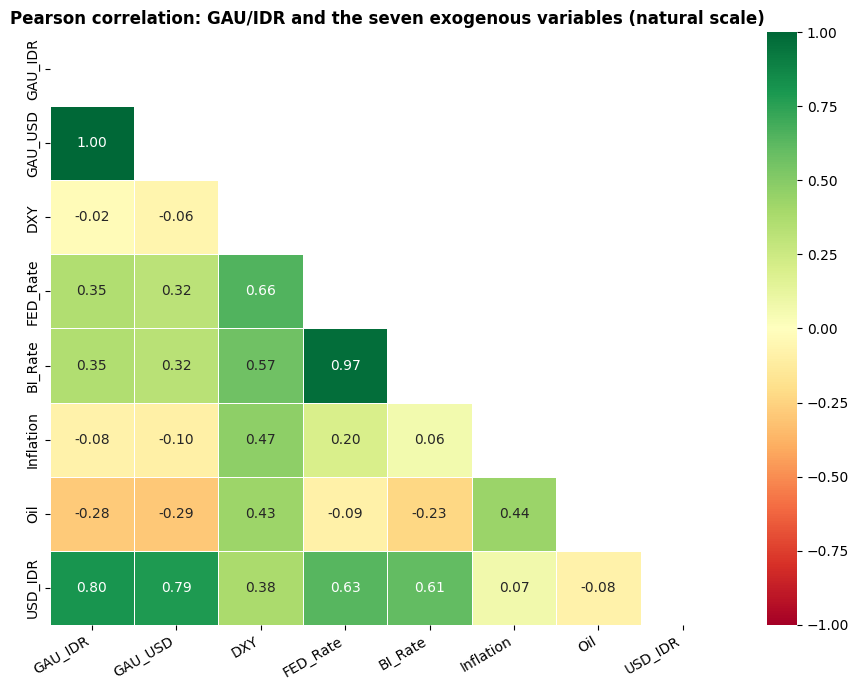

In [ ]:
# Table 2. Descriptive statistics

SATUAN = {s['name']: s['unit'] for s in [TARGET_SPEC] + EXOG_SPEC}

desc = df_all.describe().T

desc.insert(0, 'Unit', pd.Series(SATUAN))

desc['Skewness'] = df_all.agg(lambda x: skew(x.dropna()))

desc['Kurtosis'] = df_all.agg(lambda x: scipy_kurtosis(x.dropna()))

table2_descriptive = desc[[
    'Unit',
    'count',
    'mean',
    '50%',
    'std',
    'min',
    'max',
    'Skewness',
    'Kurtosis',
]].rename(columns={'50%': 'median'})

display(
    table2_descriptive.style.format({
        'count': '{:.0f}',
        'mean': '{:,.2f}',
        'median': '{:,.2f}',
        'std': '{:,.2f}',
        'min': '{:,.2f}',
        'max': '{:,.2f}',
        'Skewness': '{:.4f}',
        'Kurtosis': '{:.4f}',
    })
)

# Table. Corelation with target

corr_cols = ['GAU_IDR'] + EXOG_NATURAL

corr = df_all[corr_cols].corr()


def correlation_strength(r):

    a = abs(r)

    if a >= 0.8:
        return 'very strong'
    elif a >= 0.6:
        return 'strong'
    elif a >= 0.4:
        return 'moderate'
    elif a >= 0.2:
        return 'weak'
    else:
        return 'very weak'


corr_with_target = (
    corr['GAU_IDR']
    .drop('GAU_IDR')
    .rename('r')
    .to_frame()
    .assign(
        direction=lambda d: np.where(d['r'] > 0, 'positive', 'negative'),
        strength=lambda d: d['r'].map(correlation_strength),
    )
    .sort_values('r', key=np.abs, ascending=False)
)

display(corr_with_target.style.format({'r': '{:.3f}'}))

# Corelation matrix

fig, ax = plt.subplots(figsize=(9, 7))

sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='RdYlGn',
    center=0,
    vmin=-1,
    vmax=1,
    mask=np.triu(np.ones_like(corr, dtype=bool)),
    linewidths=0.5,
    ax=ax,
)

ax.set_title(
    'Pearson correlation: GAU/IDR and the seven exogenous variables (natural'
    ' scale)',
    fontweight='bold',
)

plt.xticks(rotation=30, ha='right')

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / 'fig_correlation_matrix.png', dpi=150, bbox_inches='tight'
)

plt.show()

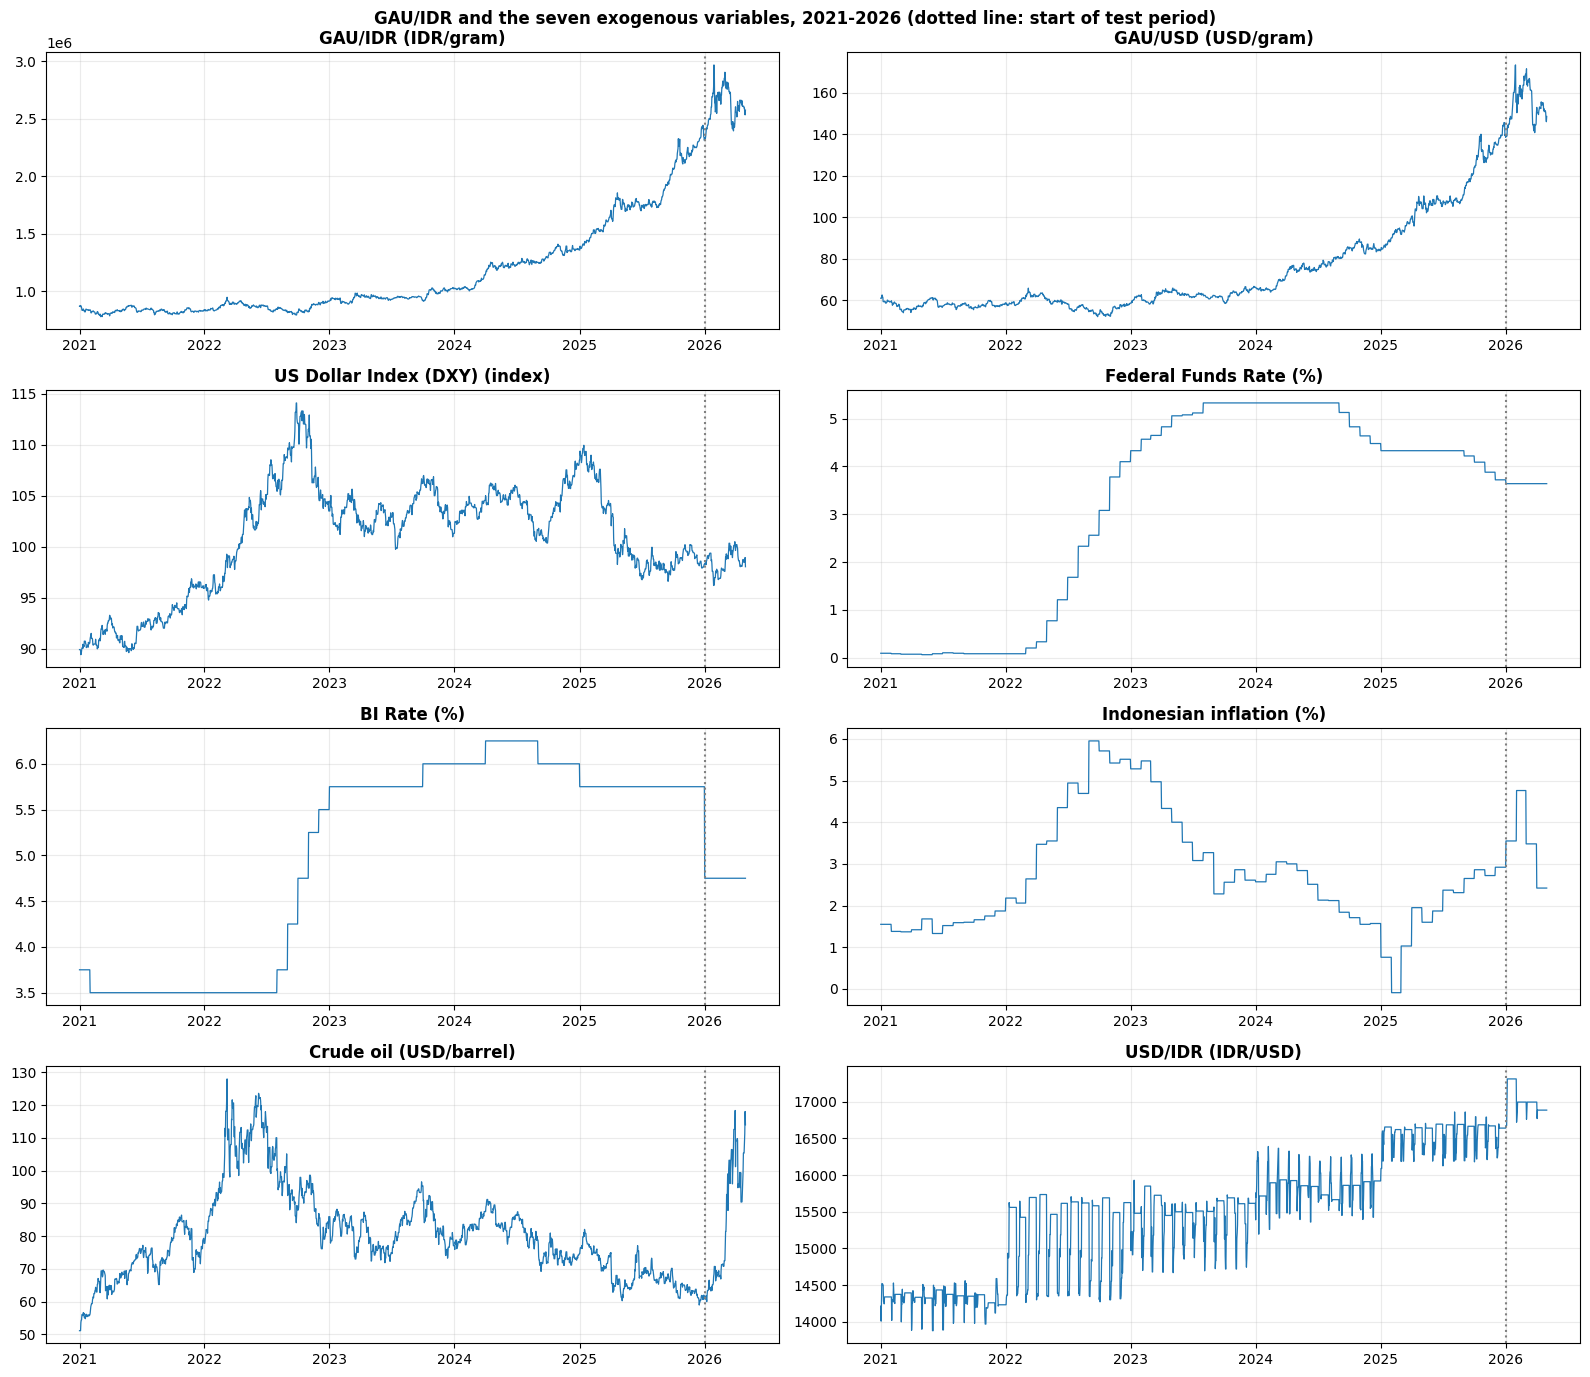

,"skewness, original","skewness, log"
GAU_IDR,1.4784,1.0094
GAU_USD,1.5186,1.1102
Oil,0.8416,0.3942
USD_IDR,-0.1367,-0.2247


In [ ]:
fig, axes = plt.subplots(4, 2, figsize=(16, 14)); axes = axes.ravel()
for ax, spec in zip(axes, [TARGET_SPEC] + EXOG_SPEC):
    ax.plot(df_all.index, df_all[spec['name']], lw=.9); ax.set_title(f"{spec['label']} ({spec['unit']})", fontweight='bold'); ax.grid(alpha=.25)
    ax.axvline(pd.Timestamp(TEST_START), color='gray', ls=':')
plt.suptitle('GAU/IDR and the seven exogenous variables, 2021-2026 (dotted line: start of test period)', fontweight='bold'); plt.tight_layout(); plt.show()

skew_table = pd.DataFrame({s['name']: {'skewness, original': skew(df_all[s['name']]), 'skewness, log': skew(np.log(df_all[s['name']]))}
                           for s in [TARGET_SPEC] + EXOG_SPEC if s['log']}).T
display(skew_table.style.format('{:.4f}'))

# **Step 2: Chronological Data Preparation**


## **Sub-step 2.1: Define Training, Testing, and Forecast-Origin Periods**


In [ ]:
period_table = pd.DataFrame([
    ('Data start', DATA_START), ('Training end', TRAIN_END), ('Test start', TEST_START), ('Test end', TEST_END),
    ('Forecast origin (T)', FORECAST_ORIGIN), ('Forecast horizon (days)', HORIZON),
    ('Mode B forecast dates', f'{FORECAST_START} to {FORECAST_END}'),
    ('Mode A evaluation window', f'{MODE_A_START} to {MODE_A_END} ({MODE_A_N} days)'),
], columns=['Parameter', 'Value'])
display(period_table.style.hide(axis='index'))

assert pd.Timestamp(DATA_START) < pd.Timestamp(TRAIN_END) < pd.Timestamp(TEST_START) <= pd.Timestamp(TEST_END)
assert pd.Timestamp(TEST_START) == pd.Timestamp(TRAIN_END) + pd.Timedelta(days=1)
assert pd.Timestamp(FORECAST_ORIGIN) == pd.Timestamp(TEST_END)
assert pd.Timestamp(FORECAST_START) == pd.Timestamp(FORECAST_ORIGIN) + pd.Timedelta(days=1)
assert (pd.Timestamp(FORECAST_END) - pd.Timestamp(FORECAST_START)).days + 1 == HORIZON

Parameter,Value
Data start,2021-01-01
Training end,2025-12-31
Test start,2026-01-01
Test end,2026-04-30
Forecast origin (T),2026-04-30
Forecast horizon (days),30
Mode B forecast dates,2026-05-01 to 2026-05-30
Mode A evaluation window,2026-01-31 to 2026-04-30 (90 days)


## **Sub-step 2.2: Apply Log Transformation**


In [ ]:
def apply_log_transform(df):
    out = df.copy()
    for spec in [TARGET_SPEC] + EXOG_SPEC:
        if spec['log']:
            if (out[spec['name']] <= 0).any():
                raise ValueError(f"Log transform requires positive values: {spec['name']}")
            out[spec['model_name']] = np.log(out[spec['name']])
        else:
            out[spec['model_name']] = out[spec['name']]
    return out

df_model = apply_log_transform(df_all)
print('Target :', TARGET)
for spec in EXOG_SPEC:
    print(f"  {spec['code']} | {spec['model_name']:12s} <- {spec['name']:10s} ({'log' if spec['log'] else 'level'})")

Target : log_GAU_IDR
  X1 | log_GAU_USD  <- GAU_USD    (log)
  X2 | DXY          <- DXY        (level)
  X3 | FED_Rate     <- FED_Rate   (level)
  X4 | BI_Rate      <- BI_Rate    (level)
  X5 | Inflation    <- Inflation  (level)
  X6 | log_Oil      <- Oil        (log)
  X7 | log_USD_IDR  <- USD_IDR    (log)


In [ ]:
LOG_VARIABLES   = [s['name'] for s in [TARGET_SPEC] + EXOG_SPEC if s['log']]
LEVEL_VARIABLES = [s['name'] for s in [TARGET_SPEC] + EXOG_SPEC if not s['log']]
assert set(LOG_VARIABLES) == {'GAU_IDR', 'GAU_USD', 'Oil', 'USD_IDR'}
assert set(LEVEL_VARIABLES) == {'DXY', 'FED_Rate', 'BI_Rate', 'Inflation'}
for s in [TARGET_SPEC] + EXOG_SPEC:
    expected = np.log(df_all[s['name']]) if s['log'] else df_all[s['name']]
    assert np.allclose(df_model[s['model_name']], expected), f"Transformation mismatch: {s['name']}"
print('Log scale  :', ', '.join(LOG_VARIABLES))
print('Level scale:', ', '.join(LEVEL_VARIABLES))

Log scale  : GAU_IDR, GAU_USD, Oil, USD_IDR
Level scale: DXY, FED_Rate, BI_Rate, Inflation


## **Sub-step 2.3: Construct Training and Testing Datasets**


In [ ]:
df_feat = df_model[[TARGET] + FEATURES].dropna()
X_all = df_feat[FEATURES].copy()      # X_t: seven exogenous regressors (model scale)
y_all = df_feat[TARGET].copy()        # y_t = log(GAU/IDR_t)
assert list(X_all.columns) == FEATURES and X_all.shape[1] == 7
print('X_all:', X_all.shape, '| y_all:', y_all.shape)
display(X_all.tail(3))

X_all: (1946, 7) | y_all: (1946,)


,log_GAU_USD,DXY,FED_Rate,BI_Rate,Inflation,log_Oil,log_USD_IDR
Date,,,,,,,
2026-04-28,4.995515,98.64,3.64,4.75,2.42,4.711870,9.734181
2026-04-29,4.984271,98.96,3.64,4.75,2.42,4.770939,9.734181
2026-04-30,5.001393,98.06,3.64,4.75,2.42,4.736286,9.734181


In [ ]:
X_train, y_train = X_all.loc[:TRAIN_END], y_all.loc[:TRAIN_END]
X_test,  y_test  = X_all.loc[TEST_START:TEST_END], y_all.loc[TEST_START:TEST_END]

assert X_train.index.max() <= pd.Timestamp(TRAIN_END), 'Training data exceed TRAIN_END.'
assert X_train.index.intersection(X_test.index).empty, 'Train/test overlap.'
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)

aligned_test_index = X_test.index[LOOKBACK:]
y_true_rp_full     = np.exp(y_test.values)
y_true_rp_aligned  = y_true_rp_full[LOOKBACK:]
assert len(y_true_rp_aligned) == len(aligned_test_index)
# explicit split and Mode A window checks
assert X_test.index.min() == pd.Timestamp(TEST_START) and X_test.index.max() == pd.Timestamp(TEST_END)
assert X_train.index.max() == pd.Timestamp(TRAIN_END) and len(X_test) == 120
assert aligned_test_index[0] == pd.Timestamp(MODE_A_START) and aligned_test_index[-1] == pd.Timestamp(MODE_A_END)
assert len(aligned_test_index) == MODE_A_N == 90

n_tr, n_te = len(X_train), len(X_test)
print(f'X_train {X_train.shape} | y_train {y_train.shape}  ({X_train.index.min().date()} -> {X_train.index.max().date()})')
print(f'X_test  {X_test.shape} | y_test  {y_test.shape}  ({X_test.index.min().date()} -> {X_test.index.max().date()})')
print(f'Train/test share: {n_tr/(n_tr+n_te):.2%} / {n_te/(n_tr+n_te):.2%} | evaluation window: '
      f'{aligned_test_index[0].date()} -> {aligned_test_index[-1].date()} ({len(aligned_test_index)} days)')

X_train (1826, 7) | y_train (1826,)  (2021-01-01 -> 2025-12-31)
X_test  (120, 7) | y_test  (120,)  (2026-01-01 -> 2026-04-30)
Train/test share: 93.83% / 6.17% | evaluation window: 2026-01-31 -> 2026-04-30 (90 days)


## **Sub-step 2.4: Define the Residual Lookback Window**

In [ ]:
n_scored = len(X_test) - LOOKBACK
print(f'LOOKBACK = {LOOKBACK} days | test days = {len(X_test)} | scored evaluation days = {n_scored}')
assert LOOKBACK == 30 and n_scored == MODE_A_N == len(aligned_test_index)

LOOKBACK = 30 days | test days = 120 | scored evaluation days = 90


## **Sub-step 2.5: Validate Chronological Separation**


In [ ]:
rows = [
    ('Training window ends on TRAIN_END', X_train.index.max() == pd.Timestamp(TRAIN_END)),
    ('Training and test indices do not overlap', X_train.index.intersection(X_test.index).empty),
    ('Test starts after the last training date', X_test.index.min() > X_train.index.max()),
    ('Test starts the day after TRAIN_END', X_test.index.min() == pd.Timestamp(TRAIN_END) + pd.Timedelta(days=1)),
    ('Forecast origin equals the last observed date', pd.Timestamp(FORECAST_ORIGIN) == X_all.index.max() == X_test.index.max() == df_all.index.max()),
    ('No training target observation after TRAIN_END', y_train.index.max() <= pd.Timestamp(TRAIN_END)),
    ('No target observation after the forecast origin in the modelling frame', y_all.index.max() <= pd.Timestamp(FORECAST_ORIGIN)),
    ('Forecast dates start after the origin and are absent from the modelling frame',
     pd.Timestamp(FORECAST_START) > pd.Timestamp(FORECAST_ORIGIN) and pd.Timestamp(FORECAST_START) not in X_all.index),
]
chk = pd.DataFrame(rows, columns=['check', 'passed'])
chk['passed'] = chk['passed'].map(lambda v: 'PASS' if bool(v) else 'FAIL')
display(chk)
assert (chk['passed'] == 'PASS').all(), 'Chronological separation failed.'

,check,passed
0,Training window ends on TRAIN_END,PASS
1,Training and test indices do not overlap,PASS
2,Test starts after the last training date,PASS
3,Test starts the day after TRAIN_END,PASS
4,Forecast origin equals the last observed date,PASS
5,No training target observation after TRAIN_END,PASS
6,No target observation after the forecast origi...,PASS
7,Forecast dates start after the origin and are ...,PASS


# **Step 3: Multivariate Prophet Baseline and Residual Extraction**

## **Sub-step 3.1: Define Prophet Configuration**


In [ ]:
display(pd.Series(PROPHET_MAIN, name='value').to_frame())
assert PROPHET_MAIN['changepoint_prior_scale'] == 0.10
assert PROPHET_MAIN['seasonality_prior_scale'] == 5.0
assert PROPHET_MAIN['interval_width'] == 0.95

,value
growth,linear
n_changepoints,25
changepoint_range,0.8
seasonality_mode,additive
changepoint_prior_scale,0.1
seasonality_prior_scale,5.0
yearly_seasonality,True
weekly_seasonality,True
daily_seasonality,False
interval_width,0.95


## **Sub-step 3.2: Fit the Multivariate Prophet Model**


In [ ]:
def prepare_prophet_dataframe(X, y=None):
    """ds + (optional) y + the seven regressor columns."""
    d = X[FEATURES].copy()
    d.insert(0, 'ds', X.index.values)
    d = d.reset_index(drop=True)
    if y is not None:
        d.insert(1, 'y', np.asarray(y, float))
    return d

def fit_prophet_seven_exogenous(X_train, y_train, params=PROPHET_MAIN):
    """Level-1 main model: Prophet with seven exogenous regressors (target: log GAU/IDR)."""
    assert len(FEATURES) == 7, 'The main Prophet model must use exactly seven exogenous regressors.'
    model = Prophet(**params)
    for regressor in FEATURES:
        model.add_regressor(regressor)
    model.fit(prepare_prophet_dataframe(X_train, y_train))
    return model

def prophet_predict(model, X, seed=SEED):
    np.random.seed(seed)
    return model.predict(prepare_prophet_dataframe(X))

In [ ]:
set_global_seed()
model_prophet = fit_prophet_seven_exogenous(X_train, y_train)
assert sorted(model_prophet.extra_regressors) == sorted(FEATURES) and len(model_prophet.extra_regressors) == 7, \
    'The main Prophet model must carry all seven exogenous regressors.'

## **Sub-step 3.3: Generate Prophet Baseline Forecast**


Fitted on 1826 training days with 7 regressors: ['log_GAU_USD', 'DXY', 'FED_Rate', 'BI_Rate', 'Inflation', 'log_Oil', 'log_USD_IDR']
Conditional one-step evaluation (actual test-period regressors):
  [Prophet (7 exogenous regressors)]  RMSE=Rp31,819  MAE=Rp26,142  MAPE=0.9964%  R²=0.929346


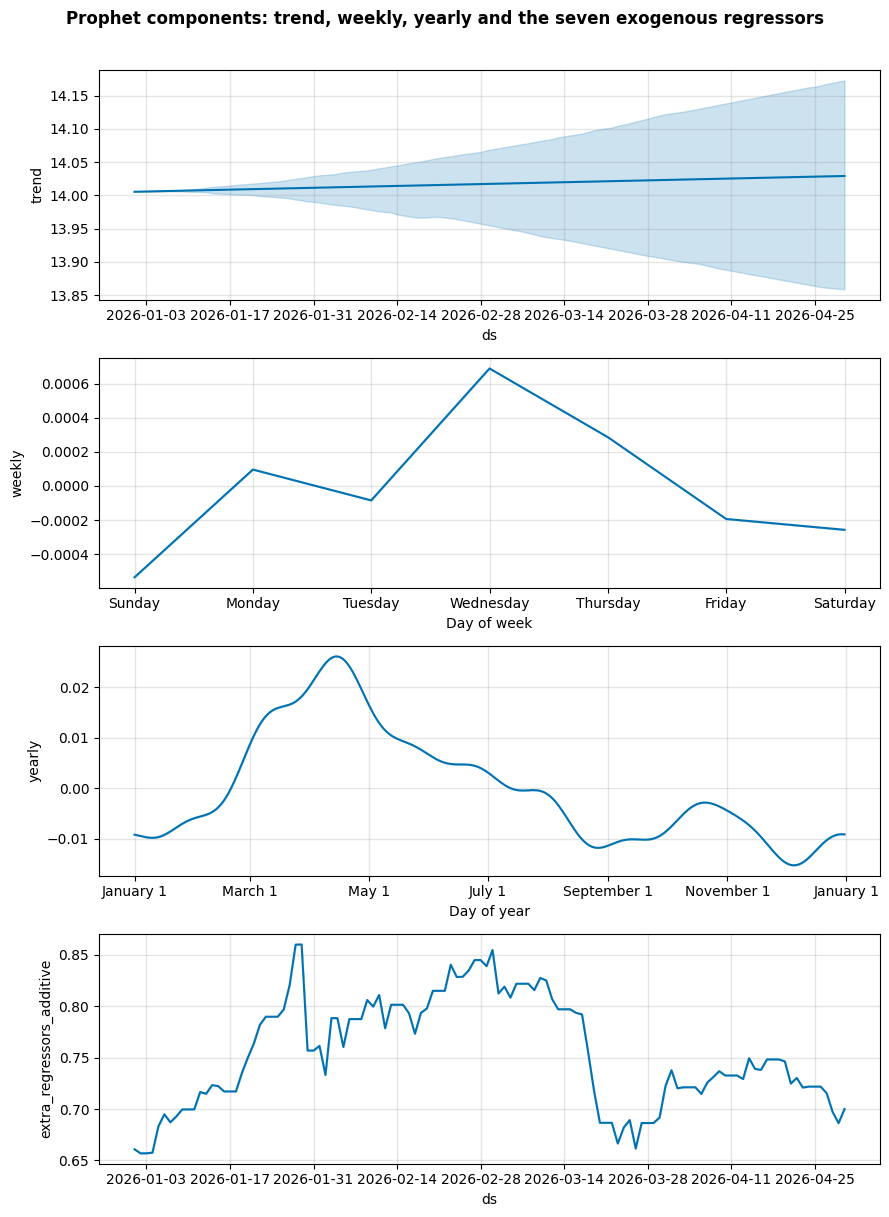

In [ ]:
fc_prophet_train = prophet_predict(model_prophet, X_train)
fc_prophet_test  = prophet_predict(model_prophet, X_test)
prophet_train_log = fc_prophet_train['yhat'].to_numpy()
prophet_test_log  = fc_prophet_test['yhat'].to_numpy()

y_pred_prophet_rp_full    = np.exp(prophet_test_log)
y_pred_prophet_rp_aligned = y_pred_prophet_rp_full[LOOKBACK:]
metrics_prophet = compute_metrics(y_true_rp_aligned, y_pred_prophet_rp_aligned, NAME_PROPHET)
print(f'Fitted on {len(X_train)} training days with {len(model_prophet.extra_regressors)} regressors: {list(model_prophet.extra_regressors)}')
print('Conditional one-step evaluation (actual test-period regressors):'); print_metrics(metrics_prophet)

fig = model_prophet.plot_components(fc_prophet_test)
fig.suptitle('Prophet components: trend, weekly, yearly and the seven exogenous regressors', fontweight='bold', y=1.01)
plt.tight_layout(); plt.show()

## **Sub-step 3.4: Extract Prophet Residuals**


,Set,Mean,Std
0,Train (n=1826),-0.000000,0.006001
1,Test (n=120),-0.000052,0.013298


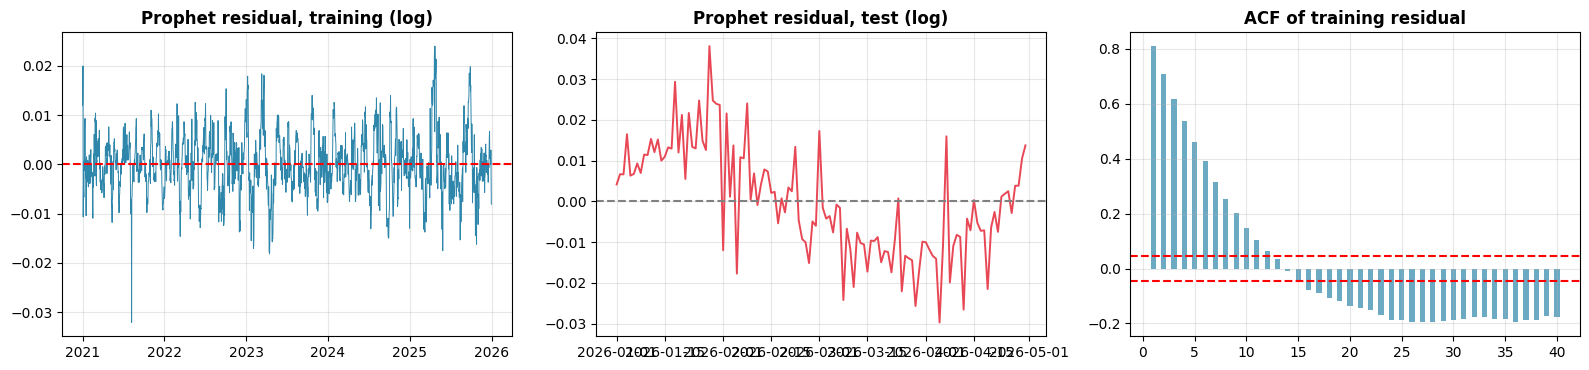

In [ ]:
def extract_prophet_residuals(y_log, prophet_yhat_log):
    """r_t = y_t - yhat_t^Prophet (log scale)."""
    return np.asarray(y_log, float) - np.asarray(prophet_yhat_log, float)

residual_train     = extract_prophet_residuals(y_train.values, prophet_train_log)
residual_test_full = extract_prophet_residuals(y_test.values,  prophet_test_log)
assert len(residual_train) == len(X_train) and len(residual_test_full) == len(X_test)

residual_stats = pd.DataFrame({'Set': ['Train (n=%d)' % len(residual_train), 'Test (n=%d)' % len(residual_test_full)],
                               'Mean': [residual_train.mean(), residual_test_full.mean()],
                               'Std':  [residual_train.std(),  residual_test_full.std()]})
display(residual_stats.style.format({'Mean': '{:.6f}', 'Std': '{:.6f}'}))

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
axes[0].plot(X_train.index, residual_train, lw=.7, color='#2E86AB'); axes[0].axhline(0, color='red', ls='--')
axes[0].set_title('Prophet residual, training (log)', fontweight='bold')
axes[1].plot(X_test.index, residual_test_full, lw=1.4, color='#E84855'); axes[1].axhline(0, color='gray', ls='--')
axes[1].set_title('Prophet residual, test (log)', fontweight='bold')
acf_vals = acf(residual_train, nlags=40, fft=True); ci = 1.96 / np.sqrt(len(residual_train))
axes[2].bar(range(1, 41), acf_vals[1:], width=.5, color='#2E86AB', alpha=.7)
axes[2].axhline(ci, color='red', ls='--'); axes[2].axhline(-ci, color='red', ls='--')
axes[2].set_title('ACF of training residual', fontweight='bold')
for ax in axes: ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUTPUT_DIR / 'fig_prophet_residual.png', dpi=150, bbox_inches='tight'); plt.show()

## **Sub-step 3.5: Scale the Residual Series**


In [ ]:
def fit_residual_scaler(residual_train):
    scaler = MinMaxScaler(feature_range=RESIDUAL_SCALER_RANGE)
    scaler.fit(np.asarray(residual_train, float).reshape(-1, 1))
    assert scaler.n_samples_seen_ == len(residual_train), 'Scaler must be fitted on training residuals only.'
    assert tuple(scaler.feature_range) == (-1, 1)
    return scaler

def scale_residuals(scaler, residuals):
    return scaler.transform(np.asarray(residuals, float).reshape(-1, 1)).ravel()

scaler_res        = fit_residual_scaler(residual_train)
residual_train_sc = scale_residuals(scaler_res, residual_train)
residual_test_sc  = scale_residuals(scaler_res, residual_test_full)
print(f'Scaler fitted on {scaler_res.n_samples_seen_} training residuals | data range '
      f'[{scaler_res.data_min_[0]:.5f}, {scaler_res.data_max_[0]:.5f}]')
print(f'Share of scaled test residuals outside [-1, 1]: {np.mean(np.abs(residual_test_sc) > 1):.1%}')

Scaler fitted on 1826 training residuals | data range [-0.03207, 0.02401]
Share of scaled test residuals outside [-1, 1]: 4.2%


In [ ]:
rows = [
    ('Scaler feature range is (-1, 1)', tuple(scaler_res.feature_range) == tuple(RESIDUAL_SCALER_RANGE)),
    ('Scaler saw exactly the training residuals', scaler_res.n_samples_seen_ == len(residual_train) == len(X_train)),
    ('Scaler minimum equals the training-residual minimum', np.isclose(scaler_res.data_min_[0], residual_train.min())),
    ('Scaler maximum equals the training-residual maximum', np.isclose(scaler_res.data_max_[0], residual_train.max())),
    ('Test residuals were transformed only, never used to fit', scaler_res.n_samples_seen_ != len(residual_train) + len(residual_test_full)),
]
chk = pd.DataFrame(rows, columns=['check', 'passed'])
chk['passed'] = chk['passed'].map(lambda v: 'PASS' if bool(v) else 'FAIL')
display(chk)
assert (chk['passed'] == 'PASS').all(), 'Residual scaler leakage check failed.'

,check,passed
0,"Scaler feature range is (-1, 1)",PASS
1,Scaler saw exactly the training residuals,PASS
2,Scaler minimum equals the training-residual mi...,PASS
3,Scaler maximum equals the training-residual ma...,PASS
4,"Test residuals were transformed only, never us...",PASS


# **Step 4: Residual LSTM and Hybrid Forecast Construction**


## **Sub-step 4.1: Construct Residual Sequences**


In [ ]:
def build_lstm_sequences(data_2d, target_1d, window):
    """Sliding windows: X[i] = data[i-window:i], y[i] = target[i]."""
    X_list, y_list = [], []
    for i in range(window, len(data_2d)):
        X_list.append(data_2d[i - window:i, :]); y_list.append(target_1d[i])
    return np.array(X_list), np.array(y_list)

def create_residual_sequences(scaled_residuals, lookback=LOOKBACK):
    arr = np.asarray(scaled_residuals, float)
    return build_lstm_sequences(arr.reshape(-1, 1), arr, lookback)

X_res_train, y_res_train = create_residual_sequences(residual_train_sc)
residual_combined_sc     = np.concatenate([residual_train_sc[-LOOKBACK:], residual_test_sc])
X_res_test,  y_res_test  = create_residual_sequences(residual_combined_sc)
assert X_res_train.shape[1:] == (LOOKBACK, 1) and len(X_res_test) == len(X_test)
assert X_res_train.shape[2] == 1, 'Residual LSTM input must be univariate (one feature).'
assert len(X_res_train) == len(X_train) - LOOKBACK, 'Training sequences must come from training residuals only.'

# Leakage check: the window for day t holds scaled residuals t-30 ... t-1 and never the residual of day t itself
for k in range(len(X_res_test)):
    assert np.allclose(X_res_test[k, :, 0], residual_combined_sc[k:k + LOOKBACK])
    assert np.isclose(y_res_test[k], residual_combined_sc[k + LOOKBACK])
for k in range(len(X_res_train)):
    assert np.allclose(X_res_train[k, :, 0], residual_train_sc[k:k + LOOKBACK])
    assert np.isclose(y_res_train[k], residual_train_sc[k + LOOKBACK])
assert np.allclose(X_res_test[1:, -1, 0], y_res_test[:-1]), 'Newest window element must be the previous day residual.'
assert np.isclose(X_res_test[0, -1, 0], residual_train_sc[-1])
print('Window check passed: prediction for day t uses residuals through t-1 only.')
print('Training sequences:', X_res_train.shape, '| Mode A sequences:', X_res_test.shape)

Window check passed: prediction for day t uses residuals through t-1 only.
Training sequences: (1796, 30, 1) | Mode A sequences: (120, 30, 1)


## **Sub-step 4.2: Define Residual LSTM Architecture**


In [ ]:
display(pd.Series(RESIDUAL_LSTM, name='value').to_frame())
print('Lookback:', LOOKBACK, '| scaler range:', RESIDUAL_SCALER_RANGE, '| seed:', SEED)

,value
units,16
dropout,0.4
l2,0.01
learning_rate,0.001
batch_size,32
max_epochs,80
patience,10
val_fraction,0.1
shuffle,False
loss,mse


Lookback: 30 | scaler range: (-1, 1) | seed: 42


In [ ]:
def build_residual_lstm(lookback=LOOKBACK, cfg=RESIDUAL_LSTM):
    model = Sequential([
        LSTM(cfg['units'], return_sequences=False, input_shape=(lookback, 1), kernel_regularizer=l2(cfg['l2'])),
        Dropout(cfg['dropout']),
        Dense(1),
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=cfg['learning_rate']), loss=cfg['loss'])
    return model

## **Sub-step 4.3: Train the Residual LSTM**


In [ ]:
def train_residual_lstm(X_seq, y_seq, cfg=RESIDUAL_LSTM):
    set_global_seed()
    model = build_residual_lstm()
    stopper = EarlyStopping(monitor='val_loss', patience=cfg['patience'], restore_best_weights=True, verbose=0)
    history = model.fit(X_seq, y_seq, validation_split=cfg['val_fraction'], epochs=cfg['max_epochs'],
                        batch_size=cfg['batch_size'], callbacks=[stopper], shuffle=cfg['shuffle'], verbose=0)
    return model, history

model_residual_lstm, hist_residual = train_residual_lstm(X_res_train, y_res_train)
print(f"Residual LSTM: {len(hist_residual.history['loss'])} epochs run | lowest val_loss = {min(hist_residual.history['val_loss']):.6f}")
model_residual_lstm.summary()

Residual LSTM: 80 epochs run | lowest val_loss = 0.017163


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_7 (LSTM)                   │ (None, 16)             │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,509 (13.71 KB)

 Trainable params: 1,169 (4.57 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,340 (9.14 KB)

In [ ]:
def _safe(fn):
    try:
        return bool(fn())
    except Exception:
        return None

_lstm  = [l for l in model_residual_lstm.layers if isinstance(l, LSTM)]
_dense = [l for l in model_residual_lstm.layers if isinstance(l, Dense)]
_drop  = [l for l in model_residual_lstm.layers if isinstance(l, Dropout)]

def _lr(m):
    return float(np.array(m.optimizer.learning_rate))

lstm_config_audit = pd.DataFrame([
    ('Univariate input (30, 1)',                 _safe(lambda: model_residual_lstm.input_shape == (None, LOOKBACK, 1) and LOOKBACK == 30)),
    ('Exactly 1 LSTM layer',                     _safe(lambda: len(_lstm) == 1)),
    ('16 LSTM units',                            _safe(lambda: _lstm[0].units == 16)),
    ('Dropout = 0.4',                            _safe(lambda: np.isclose(_drop[0].rate, 0.4))),
    ('L2 kernel regularization = 0.01',          _safe(lambda: np.isclose(float(_lstm[0].kernel_regularizer.l2), 0.01))),
    ('Dense output = 1 unit',                    _safe(lambda: len(_dense) == 1 and _dense[0].units == 1)),
    ('Adam optimizer',                           _safe(lambda: isinstance(model_residual_lstm.optimizer, tf.keras.optimizers.Adam))),
    ('Learning rate = 0.001',                    _safe(lambda: np.isclose(_lr(model_residual_lstm), 0.001))),
    ('MSE loss',                                 _safe(lambda: str(model_residual_lstm.loss).lower() in ('mse', 'mean_squared_error'))),
    ('Batch size 32 / max epochs 80',            RESIDUAL_LSTM['batch_size'] == 32 and RESIDUAL_LSTM['max_epochs'] == 80),
    ('EarlyStopping patience = 10',              RESIDUAL_LSTM['patience'] == 10),
    ('Validation = last 10% of training sequences', RESIDUAL_LSTM['val_fraction'] == 0.10 and RESIDUAL_LSTM['shuffle'] is False),
    ('Epochs run <= 80',                         len(hist_residual.history['loss']) <= 80),
    ('Trained on training sequences only',       len(X_res_train) == len(X_train) - LOOKBACK),
], columns=['check', 'passed'])
lstm_config_audit['passed'] = lstm_config_audit['passed'].map({True: 'PASS', False: 'FAIL', None: 'n/a'})
display(lstm_config_audit)
assert not (lstm_config_audit['passed'] == 'FAIL').any(), 'Residual LSTM configuration deviates from the protocol.'

,check,passed
0,"Univariate input (30, 1)",PASS
1,Exactly 1 LSTM layer,PASS
2,16 LSTM units,PASS
3,Dropout = 0.4,PASS
4,L2 kernel regularization = 0.01,PASS
5,Dense output = 1 unit,PASS
6,Adam optimizer,PASS
7,Learning rate = 0.001,PASS
8,MSE loss,PASS
9,Batch size 32 / max epochs 80,PASS


## **Sub-step 4.4: Generate LSTM Residual Corrections**

In [ ]:
def inverse_scale_residuals(scaler, scaled_values):
    """Map scaled LSTM residual predictions back to log-residual units with the training-fitted scaler."""
    return scaler.inverse_transform(np.asarray(scaled_values, float).reshape(-1, 1)).ravel()

## **Sub-step 4.5: Combine Prophet and LSTM Components**


In [ ]:
def combine_hybrid(prophet_log, predicted_residual_log, lam=LAMBDA):
    """Raw hybrid forecast on the log scale."""
    return np.asarray(prophet_log, float) + lam * np.asarray(predicted_residual_log, float)

## **Sub-step 4.6: Apply the Fixed λ Parameter**


In [ ]:
assert LAMBDA == 0.5
assert np.isclose(combine_hybrid(np.array([0.0]), np.array([1.0]))[0], LAMBDA)
assert np.isclose(combine_hybrid(np.array([2.0]), np.array([0.0]))[0], 2.0)
print(f'lambda = {LAMBDA} (fixed, not optimised in this notebook)')

lambda = 0.5 (fixed, not optimised in this notebook)


# **Step 5: Operational Exogenous Variable Forecasting**


## **Sub-step 5.1: Define Forecast Origin and Forecast Horizon**


In [ ]:
future_dates = pd.date_range(start=pd.Timestamp(FORECAST_ORIGIN) + pd.Timedelta(days=1), periods=HORIZON, freq='D', name='ds')
assert df_all.index.max() == pd.Timestamp(FORECAST_ORIGIN) and future_dates.min() > pd.Timestamp(FORECAST_ORIGIN)
assert future_dates[0] == pd.Timestamp(FORECAST_START) and future_dates[-1] == pd.Timestamp(FORECAST_END) and len(future_dates) == HORIZON == 30
print(f'Forecast origin: {FORECAST_ORIGIN} | horizon: {HORIZON} days | {future_dates[0].date()} -> {future_dates[-1].date()}')

Forecast origin: 2026-04-30 | horizon: 30 days | 2026-05-01 -> 2026-05-30


## **Sub-step 5.2: Fit Individual Prophet Models for the Seven Exogenous Variables**


In [ ]:
exog_model_config = pd.DataFrame([{'code': s['code'], 'variable': s['label'], 'scale': 'log' if s['log'] else 'level',
                                   'changepoint_prior_scale': s['cps']} for s in EXOG_SPEC])
display(exog_model_config.style.hide(axis='index'))
print('Shared Prophet settings:', EXOG_PROPHET_COMMON)

code,variable,scale,changepoint_prior_scale
X1,GAU/USD,log,0.200000
X2,US Dollar Index (DXY),level,0.200000
X3,Federal Funds Rate,level,0.030000
X4,BI Rate,level,0.030000
X5,Indonesian inflation,level,0.030000
X6,Crude oil,log,0.200000
X7,USD/IDR,log,0.200000


Shared Prophet settings: {'growth': 'linear', 'n_changepoints': 25, 'changepoint_range': 0.8, 'seasonality_mode': 'additive', 'seasonality_prior_scale': 5.0, 'yearly_seasonality': True, 'weekly_seasonality': True, 'daily_seasonality': False, 'interval_width': 0.8, 'mcmc_samples': 0, 'uncertainty_samples': 1000}


In [ ]:
def forecast_exogenous_variables(df_hist, origin, future_dates, specs=EXOG_SPEC):
    """Univariate Prophet forecast for each exogenous variable, using data up to `origin` only.
    Returns a DataFrame in MODEL space (log for logged variables), indexed by future date."""
    out = {}
    for s in specs:
        series = df_hist[s['name']].loc[:origin].dropna()
        assert series.index.max() <= pd.Timestamp(origin), f"{s['name']}: training data exceed the forecast origin."
        y = np.log(series) if s['log'] else series.copy()
        m = Prophet(changepoint_prior_scale=s['cps'], **EXOG_PROPHET_COMMON)
        m.fit(pd.DataFrame({'ds': y.index, 'y': y.values}))
        out[s['model_name']] = m.predict(pd.DataFrame({'ds': future_dates}))['yhat'].to_numpy()
    return pd.DataFrame(out, index=future_dates)

## **Sub-step 5.3: Generate the Seven Exogenous Forecasts**


In [ ]:
exog_forecast_model_space = forecast_exogenous_variables(df_all, FORECAST_ORIGIN, future_dates)
assert exog_forecast_model_space.shape == (HORIZON, 7) and list(exog_forecast_model_space.columns) == FEATURES
assert not exog_forecast_model_space.isna().any().any() and exog_forecast_model_space.index.equals(future_dates)
print('Seven exogenous forecasts generated from data up to', FORECAST_ORIGIN, '| horizon', HORIZON, 'days')
print('Forecast ranges (model scale):')
display(exog_forecast_model_space.agg(['min', 'max']).T.rename(columns={'min': 'min', 'max': 'max'}))

Seven exogenous forecasts generated from data up to 2026-04-30 | horizon 30 days
Forecast ranges (model scale):


,min,max
log_GAU_USD,5.064478,5.084538
DXY,96.566855,97.998685
FED_Rate,3.637870,3.658672
BI_Rate,4.680177,4.713174
Inflation,3.885818,4.114087
log_Oil,4.614375,4.652616
log_USD_IDR,9.729987,9.735948


## **Sub-step 5.4: Construct the Future Exogenous Regressor Matrix**


future_exog: (30, 8) | all seven regressors present: ['GAU_USD', 'USD_IDR', 'DXY', 'FED_Rate', 'BI_Rate', 'Oil', 'Inflation']


,ds,GAU_USD,USD_IDR,DXY,FED_Rate,BI_Rate,Oil,Inflation
0,2026-05-01,158.605350,16914.870200,97.998685,3.637870,4.712578,100.924781,3.885818
1,2026-05-02,158.463115,16901.790815,97.998527,3.640424,4.712827,101.003955,3.894951
2,2026-05-03,158.336191,16905.871464,97.996274,3.642053,4.712446,101.083451,3.907929


,ds,GAU_USD,USD_IDR,DXY,FED_Rate,BI_Rate,Oil,Inflation
28,2026-05-29,161.505315,16840.059220,96.615320,3.642693,4.680714,104.638909,4.114087
29,2026-05-30,161.454686,16833.175645,96.566855,3.640930,4.680177,104.858980,4.111594


,last observed (30 Apr),"forecast, 1 May","forecast, 30 May",forecast min,forecast max,"change, 30 Apr to 30 May (%)"
GAU_USD,148.6200,158.6053,161.4547,158.2978,161.5053,8.6359
USD_IDR,"16,885.0000","16,914.8702","16,833.1756","16,814.3263","16,914.8702",-0.3069
DXY,98.0600,97.9987,96.5669,96.5669,97.9987,-1.5227
FED_Rate,3.6400,3.6379,3.6409,3.6379,3.6587,0.0256
BI_Rate,4.7500,4.7126,4.6802,4.6802,4.7132,-1.4700
Oil,114.0100,100.9248,104.8590,100.9248,104.8590,-8.0265
Inflation,2.4200,3.8858,4.1116,3.8858,4.1141,69.9006


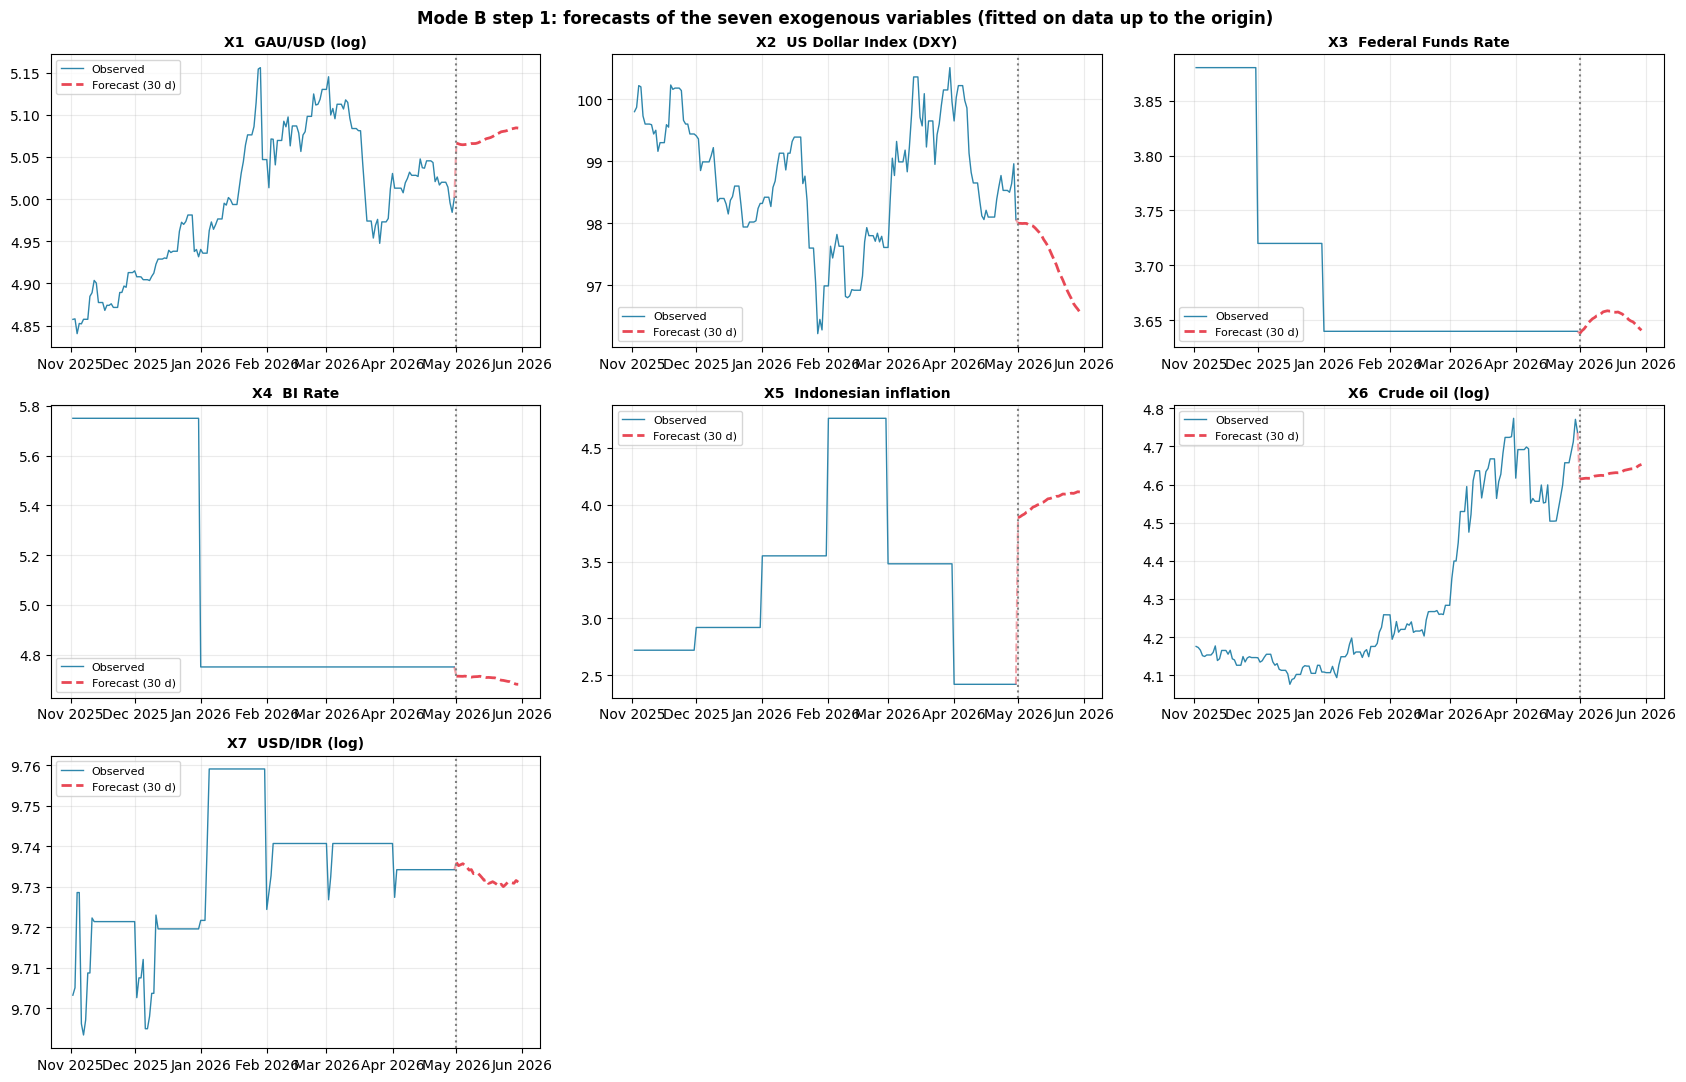

In [ ]:
def build_future_exogenous_matrix(forecast_model_space, specs=EXOG_SPEC):
    """Returns (future_exog in natural units, future_regressors in Prophet model space)."""
    ds = forecast_model_space.index
    future_exog = pd.DataFrame({'ds': ds})
    for name in FUTURE_EXOG_COLUMNS:
        s = next(x for x in specs if x['name'] == name)
        v = forecast_model_space[s['model_name']].to_numpy()
        future_exog[name] = np.exp(v) if s['log'] else v
    future_regressors = forecast_model_space[FEATURES].copy()
    future_regressors.insert(0, 'ds', ds.values)
    future_regressors = future_regressors.reset_index(drop=True)
    return future_exog.reset_index(drop=True), future_regressors

future_exog, future_regressors = build_future_exogenous_matrix(exog_forecast_model_space)

assert future_exog.shape[0] == HORIZON == 30
assert list(future_exog.columns) == ['ds'] + FUTURE_EXOG_COLUMNS
assert list(future_regressors.columns) == ['ds'] + FEATURES and future_regressors.shape[0] == HORIZON
assert not future_exog.isna().any().any() and not future_regressors.isna().any().any()
assert future_exog['ds'].min() == pd.Timestamp('2026-05-01') and future_exog['ds'].max() == pd.Timestamp('2026-05-30')
assert pd.DatetimeIndex(future_exog['ds']).equals(future_dates) and future_dates.intersection(df_all.index).empty
assert len(FUTURE_EXOG_COLUMNS) == 7 and 'GAU_IDR' not in future_exog.columns and TARGET not in future_regressors.columns
print('future_exog:', future_exog.shape, '| all seven regressors present:', FUTURE_EXOG_COLUMNS)
display(future_exog.head(3)); display(future_exog.tail(2))

last_obs = df_all.loc[FORECAST_ORIGIN, FUTURE_EXOG_COLUMNS]
summary = pd.DataFrame({'last observed (30 Apr)': last_obs,
                        'forecast, 1 May': future_exog.set_index('ds').iloc[0][FUTURE_EXOG_COLUMNS],
                        'forecast, 30 May': future_exog.set_index('ds').iloc[-1][FUTURE_EXOG_COLUMNS],
                        'forecast min': future_exog[FUTURE_EXOG_COLUMNS].min(), 'forecast max': future_exog[FUTURE_EXOG_COLUMNS].max()})
summary['change, 30 Apr to 30 May (%)'] = (summary['forecast, 30 May'] / summary['last observed (30 Apr)'] - 1) * 100
display(summary.style.format('{:,.4f}'))

fig, axes = plt.subplots(3, 3, figsize=(17, 11)); axes = axes.ravel(); HIST = 180
for ax, s in zip(axes, EXOG_SPEC):
    hist = df_all[s['name']].iloc[-HIST:]
    h_plot = np.log(hist) if s['log'] else hist
    fut = exog_forecast_model_space[s['model_name']]
    ax.plot(hist.index, h_plot, color='#2E86AB', lw=1, label='Observed')
    ax.plot([hist.index[-1], fut.index[0]], [h_plot.iloc[-1], fut.iloc[0]], color='#E84855', ls='--', alpha=.5)
    ax.plot(fut.index, fut, color='#E84855', ls='--', lw=2, label=f'Forecast ({HORIZON} d)')
    ax.axvline(fut.index[0], color='gray', ls=':')
    ax.set_title(f"{s['code']}  {s['label']}" + (' (log)' if s['log'] else ''), fontweight='bold', fontsize=10)
    ax.legend(fontsize=8); ax.grid(alpha=.25); ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
for ax in axes[len(EXOG_SPEC):]: ax.set_visible(False)
plt.suptitle('Mode B step 1: forecasts of the seven exogenous variables (fitted on data up to the origin)', fontweight='bold')
plt.tight_layout(); plt.savefig(OUTPUT_DIR / 'fig_exogenous_forecasts.png', dpi=150, bbox_inches='tight'); plt.show()

## **Sub-step 5.5: Perform Exogenous Leakage Validation**


In [ ]:
exog_leak_rows = []
for s in EXOG_SPEC:
    cutoff = df_all[s['name']].loc[:FORECAST_ORIGIN].dropna().index.max()
    actual_after = series_raw[s['name']].loc[future_dates[0]:future_dates[-1]].dropna()
    fc_nat = future_exog.set_index('ds')[s['name']]
    identical = bool(len(actual_after) and np.allclose(fc_nat.reindex(actual_after.index).to_numpy(),
                                                       actual_after.to_numpy(), rtol=1e-9, atol=0))
    exog_leak_rows.append({'variable': s['label'], 'training cutoff': cutoff.date(),
                           'cutoff <= origin': bool(cutoff <= pd.Timestamp(FORECAST_ORIGIN)),
                           'actual post-origin values in raw file (unused)': len(actual_after),
                           'forecast identical to actuals': identical,
                           'forecast days': int(fc_nat.notna().sum())})
df_exog_leak = pd.DataFrame(exog_leak_rows)
display(df_exog_leak.style.hide(axis='index'))

rows = [
    ('All training cutoffs are on or before the forecast origin', df_exog_leak['cutoff <= origin'].all()),
    ('No forecast is numerically identical to an actual post-origin value', not df_exog_leak['forecast identical to actuals'].any()),
    ('future_exog has 30 rows and 1 + 7 columns', future_exog.shape == (HORIZON, 1 + len(FUTURE_EXOG_COLUMNS))),
    ('future_regressors has 30 rows and 1 + 7 columns', future_regressors.shape == (HORIZON, 1 + len(FEATURES))),
    ('Forecast dates start after the origin and do not overlap the history', future_dates.min() > pd.Timestamp(FORECAST_ORIGIN) and future_dates.intersection(df_all.index).empty),
    ('The target is not a column of either future matrix', 'GAU_IDR' not in future_exog.columns and TARGET not in future_regressors.columns),
    ('Every future column holds forecasts (no missing values)', not future_exog.isna().any().any() and not future_regressors.isna().any().any()),
]
chk = pd.DataFrame(rows, columns=['check', 'passed'])
chk['passed'] = chk['passed'].map(lambda v: 'PASS' if bool(v) else 'FAIL')
display(chk)
assert (chk['passed'] == 'PASS').all(), 'Exogenous leakage validation failed.'

variable,training cutoff,cutoff <= origin,actual post-origin values in raw file (unused),forecast identical to actuals,forecast days
GAU/USD,2026-04-30,True,1,False,30
US Dollar Index (DXY),2026-04-30,True,1,False,30
Federal Funds Rate,2026-04-30,True,0,False,30
BI Rate,2026-04-30,True,0,False,30
Indonesian inflation,2026-04-30,True,0,False,30
Crude oil,2026-04-30,True,1,False,30
USD/IDR,2026-04-30,True,3,False,30


,check,passed
0,All training cutoffs are on or before the fore...,PASS
1,No forecast is numerically identical to an act...,PASS
2,future_exog has 30 rows and 1 + 7 columns,PASS
3,future_regressors has 30 rows and 1 + 7 columns,PASS
4,Forecast dates start after the origin and do n...,PASS
5,The target is not a column of either future ma...,PASS
6,Every future column holds forecasts (no missin...,PASS


# **Step 6: Recursive Forecasting and Boundary-Continuity Re-Anchoring**


## **Sub-step 6.1: Initialize the Residual Window**


In [ ]:
# The initial window = the 30 most recent observed Prophet residuals available at the forecast origin (1-30 April 2026)

residual_window_at_origin_sc = residual_test_sc[-LOOKBACK:]
initial_window_dates = X_test.index[-LOOKBACK:]
assert initial_window_dates[-1] == pd.Timestamp(FORECAST_ORIGIN) and len(initial_window_dates) == LOOKBACK
assert np.allclose(residual_window_at_origin_sc, scale_residuals(scaler_res, residual_test_full[-LOOKBACK:]))

## **Sub-step 6.2: Generate the First Recursive Forecast**


In [ ]:
def run_recursive_operational_forecast(prophet_model, future_regressors, residual_lstm, scaler,
                                       residual_window_sc, lam=LAMBDA, seed=SEED):
    """Mode B. Returns a dict of arrays indexed by horizon step h = 1..H (log scale).
    The initial window holds the 30 most recent OBSERVED Prophet residuals at the forecast origin.
    From h = 2 onward the window contains predicted residuals only; no actual residual, target or
    exogenous value from the forecast horizon is used."""
    np.random.seed(seed)
    fc = prophet_model.predict(future_regressors[['ds'] + FEATURES])
    prophet_log = fc['yhat'].to_numpy()
    window = np.asarray(residual_window_sc, float).copy()
    assert window.shape == (LOOKBACK,), 'Residual window must hold exactly LOOKBACK observed residuals.'
    H = len(prophet_log)
    res_sc, res_log, raw = np.zeros(H), np.zeros(H), np.zeros(H)
    input_windows = np.zeros((H, LOOKBACK))
    for h in range(H):
        input_windows[h] = window
        nxt = float(residual_lstm(window.reshape(1, LOOKBACK, 1), training=False).numpy().ravel()[0])
        res_sc[h]  = nxt
        res_log[h] = float(inverse_scale_residuals(scaler, [nxt])[0])
        raw[h]     = prophet_log[h] + lam * res_log[h]
        window     = np.append(window[1:], nxt)
    return dict(prophet_log=prophet_log, prophet_lower_log=fc['yhat_lower'].to_numpy(),
                prophet_upper_log=fc['yhat_upper'].to_numpy(), predicted_residual_sc=res_sc,
                predicted_residual_log=res_log, raw_hybrid_log=raw, input_windows=input_windows)

## **Sub-step 6.3: Update the Residual Window**


## **Sub-step 6.4: Repeat Recursive Forecasting**



In [ ]:
modeB = run_recursive_operational_forecast(model_prophet, future_regressors, model_residual_lstm,
                                           scaler_res, residual_window_at_origin_sc)

# Verification of the recursive update: step 1 = observed window; step h+1 = observed tail + predictions only
_iw, _pr = modeB['input_windows'], modeB['predicted_residual_sc']
assert np.allclose(_iw[0], residual_window_at_origin_sc)
for h in range(min(len(_pr), LOOKBACK)):
    assert np.allclose(_iw[h][:LOOKBACK - h], residual_window_at_origin_sc[h:]), 'Observed part of the window is inconsistent.'
    assert np.allclose(_iw[h][LOOKBACK - h:], _pr[:h]), 'Window must contain predicted residuals only after step 1.'
print(f"Initial residual window: observed residuals {initial_window_dates[0].date()} -> {initial_window_dates[-1].date()}")
print(f"Prophet forecast (log): {modeB['prophet_log'].min():.4f} -> {modeB['prophet_log'].max():.4f}")
print(f"Predicted residual (log): {modeB['predicted_residual_log'].min():.6f} -> {modeB['predicted_residual_log'].max():.6f} "
      f"(mean {modeB['predicted_residual_log'].mean():.6f})")

Initial residual window: observed residuals 2026-04-01 -> 2026-04-30
Prophet forecast (log): 14.8136 -> 14.8264
Predicted residual (log): -0.000462 -> 0.010539 (mean 0.002652)


## **Sub-step 6.5: Construct the Raw Hybrid Forecast**


In [ ]:
raw_hybrid_log = modeB['raw_hybrid_log']
raw_hybrid_rp  = np.exp(raw_hybrid_log)
last_observed_log = float(y_all.loc[FORECAST_ORIGIN])        # y_T
last_observed_rp  = float(np.exp(last_observed_log))         # GAU/IDR on 30 April 2026
assert np.isclose(last_observed_rp, df_all.loc[FORECAST_ORIGIN, 'GAU_IDR'])
print(f'Last observed GAU/IDR ({FORECAST_ORIGIN}): Rp {last_observed_rp:,.0f}/gram')
print(f'Raw hybrid forecast, day 1: Rp {raw_hybrid_rp[0]:,.0f}/gram | raw jump at the boundary: {(raw_hybrid_rp[0]/last_observed_rp-1)*100:+.4f}%')

Last observed GAU/IDR (2026-04-30): Rp 2,573,810/gram
Raw hybrid forecast, day 1: Rp 2,740,307/gram | raw jump at the boundary: +6.4689%


## **Sub-step 6.6: Calculate Boundary Offset δ**


In [ ]:
def compute_boundary_offset(raw_log, last_observed_log):
    """delta = y_T - raw hybrid forecast of the first horizon step (log scale)."""
    return float(last_observed_log - raw_log[0])


delta = compute_boundary_offset(raw_hybrid_log, last_observed_log)
print(f'delta = {delta:.6f} (log scale)')

delta = -0.062683 (log scale)


## **Sub-step 6.7: Apply Boundary-Continuity Re-Anchoring**


In [ ]:
def apply_boundary_reanchoring(raw_log, delta):
    """Uniform additive offset on the log scale, applied to every horizon step."""
    return np.asarray(raw_log, float) + delta


final_reanchored_log = apply_boundary_reanchoring(raw_hybrid_log, delta)

## **Sub-step 6.8: Generate Final Operational GAU/IDR Forecast**


In [ ]:
final_reanchored_rp = np.exp(final_reanchored_log)

In [ ]:
lam_vec = np.full(HORIZON, LAMBDA)
operational_forecast = pd.DataFrame({
    'date': future_dates,
    'actual_anchor': last_observed_log,                                  # y_T (log GAU/IDR on 30 April 2026)
    'Prophet_7_exogenous_forecast': modeB['prophet_log'],
    'predicted_residual': modeB['predicted_residual_log'],
    'lambda': lam_vec,
    'raw_hybrid_forecast': raw_hybrid_log,
    'delta': delta,
    'final_reanchored_forecast': final_reanchored_log,
    'actual_anchor_idr_per_gram': last_observed_rp,
    'prophet_idr_per_gram': np.exp(modeB['prophet_log']),
    'raw_hybrid_idr_per_gram': raw_hybrid_rp,
    'final_idr_per_gram': final_reanchored_rp,
    'cond_prophet_interval_lower_idr_per_gram': np.exp(modeB['prophet_lower_log'] + LAMBDA * modeB['predicted_residual_log'] + delta),
    'cond_prophet_interval_upper_idr_per_gram': np.exp(modeB['prophet_upper_log'] + LAMBDA * modeB['predicted_residual_log'] + delta),
})
assert operational_forecast['date'].nunique() == HORIZON == len(operational_forecast)
operational_forecast.to_csv(OUTPUT_DIR / 'operational_forecast_may2026.csv', index=False)
future_exog.to_csv(OUTPUT_DIR / 'future_exog_may2026.csv', index=False)

view = operational_forecast.set_index('date')[['prophet_idr_per_gram', 'raw_hybrid_idr_per_gram', 'final_idr_per_gram',
                                               'cond_prophet_interval_lower_idr_per_gram', 'cond_prophet_interval_upper_idr_per_gram']]
display(view.style.format('Rp {:,.0f}'))
print(f"Final range: Rp {final_reanchored_rp.min():,.0f} - Rp {final_reanchored_rp.max():,.0f}/gram | "
      f"30 May 2026: Rp {final_reanchored_rp[-1]:,.0f}/gram")

,prophet_idr_per_gram,raw_hybrid_idr_per_gram,final_idr_per_gram,cond_prophet_interval_lower_idr_per_gram,cond_prophet_interval_upper_idr_per_gram
date,,,,,
2026-05-01 00:00:00,"Rp 2,725,904","Rp 2,740,307","Rp 2,573,810","Rp 2,540,774","Rp 2,607,334"
2026-05-02 00:00:00,"Rp 2,721,755","Rp 2,735,489","Rp 2,569,285","Rp 2,538,717","Rp 2,601,518"
2026-05-03 00:00:00,"Rp 2,717,470","Rp 2,730,097","Rp 2,564,220","Rp 2,530,982","Rp 2,597,127"
2026-05-04 00:00:00,"Rp 2,717,271","Rp 2,728,710","Rp 2,562,918","Rp 2,531,842","Rp 2,595,454"
2026-05-05 00:00:00,"Rp 2,716,312","Rp 2,726,595","Rp 2,560,931","Rp 2,529,342","Rp 2,595,111"
2026-05-06 00:00:00,"Rp 2,717,787","Rp 2,726,986","Rp 2,561,299","Rp 2,530,562","Rp 2,592,232"
2026-05-07 00:00:00,"Rp 2,716,280","Rp 2,724,434","Rp 2,558,902","Rp 2,525,830","Rp 2,592,297"
2026-05-08 00:00:00,"Rp 2,715,682","Rp 2,722,829","Rp 2,557,394","Rp 2,522,480","Rp 2,590,246"
2026-05-09 00:00:00,"Rp 2,714,328","Rp 2,720,494","Rp 2,555,201","Rp 2,523,804","Rp 2,587,640"


Final range: Rp 2,553,030 - Rp 2,580,582/gram | 30 May 2026: Rp 2,578,118/gram


## **Sub-step 6.9: Validate Boundary Continuity**


In [ ]:
def validate_boundary_continuity(raw_log, final_log, last_observed_log, delta, tol=1e-10):
    checks = {
        'Day-1 final forecast equals last observation (log scale)': bool(np.isclose(final_log[0], last_observed_log, atol=tol)),
        'Constant delta across the horizon': bool(np.allclose(final_log - raw_log, delta, atol=tol)),
        'Relative trajectory unchanged (consecutive differences)': bool(np.allclose(np.diff(final_log), np.diff(raw_log), atol=tol)),
        'Horizon length preserved': len(final_log) == len(raw_log) == HORIZON,
        'Delta equals last observed log minus raw day-1 forecast': bool(np.isclose(delta, last_observed_log - raw_log[0], atol=tol)),
    }
    return checks

continuity_checks = validate_boundary_continuity(raw_hybrid_log, final_reanchored_log, last_observed_log, delta)

print(f'delta = y_T - raw_forecast(T+1) = {delta:.6f} (log scale, approx. {(np.exp(delta)-1)*100:+.4f}% in level)')
print(f'Day-1 final forecast: Rp {final_reanchored_rp[0]:,.0f}/gram | last observation: Rp {last_observed_rp:,.0f}/gram')
for k, v in continuity_checks.items():
    print(f"  {'PASS' if v else 'FAIL'}  {k}")
assert all(continuity_checks.values()), 'Boundary-continuity validation failed.'

delta = y_T - raw_forecast(T+1) = -0.062683 (log scale, approx. -6.0758% in level)
Day-1 final forecast: Rp 2,573,810/gram | last observation: Rp 2,573,810/gram
  PASS  Day-1 final forecast equals last observation (log scale)
  PASS  Constant delta across the horizon
  PASS  Relative trajectory unchanged (consecutive differences)
  PASS  Horizon length preserved
  PASS  Delta equals last observed log minus raw day-1 forecast


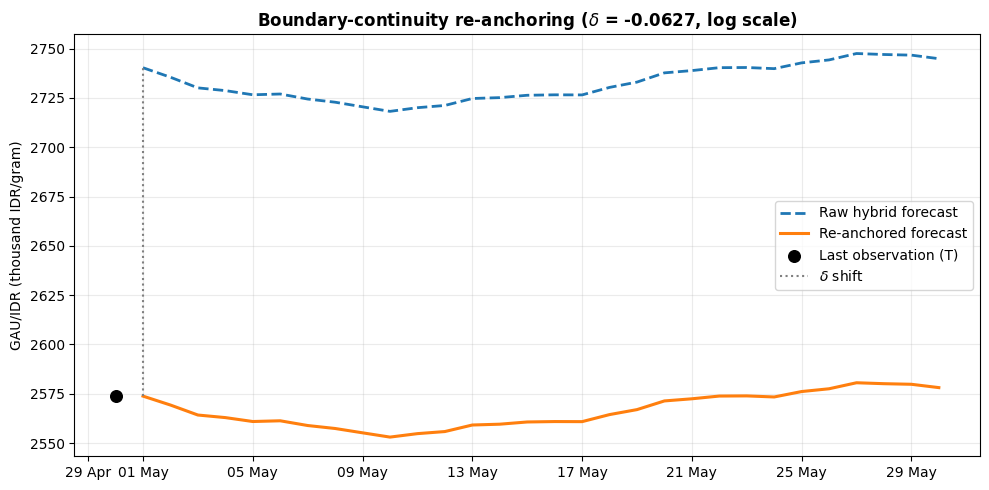

In [ ]:
# Effect of the boundary shift
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(future_dates, raw_hybrid_rp / 1000, ls='--', lw=2, label='Raw hybrid forecast')
ax.plot(future_dates, final_reanchored_rp / 1000, lw=2.2, label='Re-anchored forecast')
ax.scatter([pd.Timestamp(FORECAST_ORIGIN)], [last_observed_rp / 1000], s=70, color='black', zorder=5, label='Last observation (T)')
ax.plot([future_dates[0]] * 2, [final_reanchored_rp[0] / 1000, raw_hybrid_rp[0] / 1000], ':', color='gray', label=r'$\delta$ shift')
ax.set_title(f'Boundary-continuity re-anchoring ($\\delta$ = {delta:.4f}, log scale)', fontweight='bold')
ax.set_ylabel('GAU/IDR (thousand IDR/gram)'); ax.grid(alpha=.25); ax.legend()
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b')); plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_boundary_continuity.png', dpi=200, bbox_inches='tight'); plt.show()

# **Step 7: Method Validation and Reproducibility**


## **Sub-step 7.1: Conditional One-Step Evaluation**


Mode A: conditional one-step-ahead evaluation (actual contemporaneous exogenous variables)
Evaluation window: 2026-01-31 -> 2026-04-30 (90 days)
  [Prophet (7 exogenous regressors)]  RMSE=Rp31,819  MAE=Rp26,142  MAPE=0.9964%  R²=0.929346
  [Hybrid Prophet-LSTM (residual correction)]  RMSE=Rp27,546  MAE=Rp21,432  MAPE=0.8150%  R²=0.947051


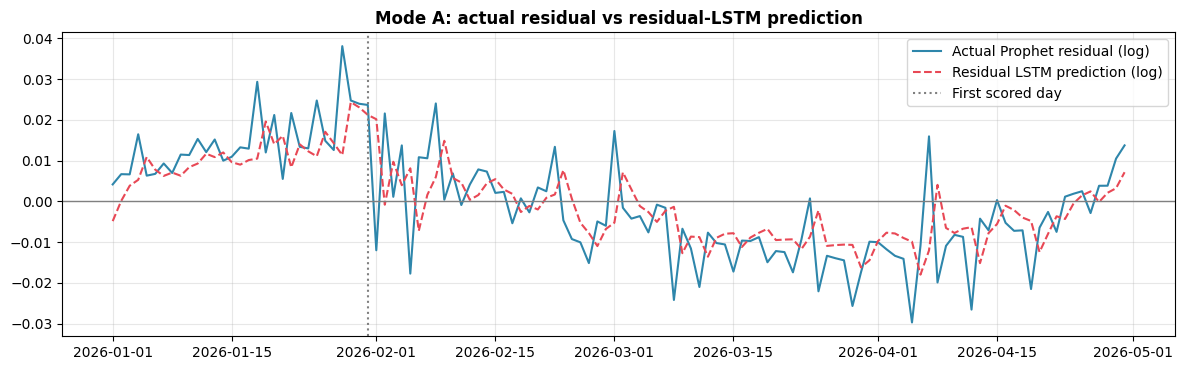

In [ ]:
def run_conditional_one_step_evaluation(prophet_model, residual_lstm, scaler, X_test, y_test, residual_train_sc, lam=LAMBDA):
    """Mode A. Actual contemporaneous regressors (day t) and actual residuals through day t-1."""
    assert list(X_test.columns) == FEATURES and len(FEATURES) == 7
    fc = prophet_predict(prophet_model, X_test)
    prophet_log = fc['yhat'].to_numpy()
    residual_test = extract_prophet_residuals(y_test.values, prophet_log)
    residual_test_sc = scale_residuals(scaler, residual_test)
    combined = np.concatenate([residual_train_sc[-LOOKBACK:], residual_test_sc])
    X_seq, _ = create_residual_sequences(combined)
    assert len(X_seq) == len(X_test) and X_seq.shape[1:] == (LOOKBACK, 1)
    assert np.isclose(X_seq[0, -1, 0], residual_train_sc[-1]) and np.allclose(X_seq[1:, -1, 0], residual_test_sc[:-1])
    pred_sc  = residual_lstm.predict(X_seq, verbose=0).ravel()
    pred_log = inverse_scale_residuals(scaler, pred_sc)
    hybrid_log = combine_hybrid(prophet_log, pred_log, lam)
    assert np.allclose(hybrid_log, prophet_log + lam * pred_log) and lam == 0.5
    return dict(prophet_log=prophet_log, residual_test=residual_test, residual_test_sc=residual_test_sc,
                predicted_residual_log=pred_log, hybrid_log=hybrid_log)

modeA = run_conditional_one_step_evaluation(model_prophet, model_residual_lstm, scaler_res,
                                                X_test, y_test, residual_train_sc)
y_pred_hybrid_log = modeA['hybrid_log'][LOOKBACK:]
y_pred_hybrid_rp  = np.exp(y_pred_hybrid_log)
assert len(y_pred_hybrid_rp) == len(aligned_test_index)
assert np.allclose(modeA['prophet_log'], prophet_test_log)

metrics_hybrid = compute_metrics(y_true_rp_aligned, y_pred_hybrid_rp, NAME_HYBRID)
print('Mode A: conditional one-step-ahead evaluation (actual contemporaneous exogenous variables)')
print(f'Evaluation window: {aligned_test_index[0].date()} -> {aligned_test_index[-1].date()} ({len(aligned_test_index)} days)')
print_metrics(metrics_prophet); print_metrics(metrics_hybrid)

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(X_test.index, modeA['residual_test'], color='#2E86AB', label='Actual Prophet residual (log)')
ax.plot(X_test.index, modeA['predicted_residual_log'], color='#E84855', ls='--', label='Residual LSTM prediction (log)')
ax.axvline(aligned_test_index[0], color='gray', ls=':', label='First scored day')
ax.axhline(0, color='gray', lw=1); ax.legend(); ax.grid(alpha=.3)
ax.set_title('Mode A: actual residual vs residual-LSTM prediction', fontweight='bold')
plt.tight_layout(); plt.savefig(OUTPUT_DIR / 'fig_modeA_residual_prediction.png', dpi=150, bbox_inches='tight'); plt.show()

## **Sub-step 7.2: Operational Protocol Validation**


In [ ]:
def run_protocol_checks():
    checks = [
        ('Main Prophet carries all seven exogenous regressors', sorted(model_prophet.extra_regressors) == sorted(FEATURES) and len(FEATURES) == 7),
        ('Prophet trained on training window only', X_train.index.max() <= pd.Timestamp(TRAIN_END)),
        ('Residual scaler fitted on training residuals only', scaler_res.n_samples_seen_ == len(X_train)),
        ('Residual LSTM uses a univariate residual window', model_residual_lstm.input_shape == (None, LOOKBACK, 1)),
        ('Exogenous models fitted on data up to the origin only', df_all.index.max() <= pd.Timestamp(FORECAST_ORIGIN)),
        ('future_exog has 30 rows', future_exog.shape[0] == 30),
        ('future_exog has all seven exogenous variables', set(FUTURE_EXOG_COLUMNS) <= set(future_exog.columns)),
        ('Forecast dates start after the origin', future_dates.min() > pd.Timestamp(FORECAST_ORIGIN)),
        ('Target is not a column of the future regressor matrix', TARGET not in future_regressors.columns and 'GAU_IDR' not in future_exog.columns),
        ('Residual window at origin holds LOOKBACK observed residuals', len(residual_window_at_origin_sc) == LOOKBACK),
        ('Lambda used in Mode A and Mode B is identical', bool(np.all(operational_forecast['lambda'] == LAMBDA))),
        ('Raw and final forecasts stored separately', not np.allclose(operational_forecast['raw_hybrid_forecast'], operational_forecast['final_reanchored_forecast'])
                                                         or np.isclose(delta, 0)),
    ] + [(k, v) for k, v in continuity_checks.items()]
    return pd.DataFrame(checks, columns=['check', 'passed'])

protocol_checks = run_protocol_checks()
display(protocol_checks.style.apply(lambda c: ['background-color:#c6efce' if v else 'background-color:#ffc7ce' for v in c], subset=['passed']))
assert protocol_checks['passed'].all(), 'Protocol validation failed.'
print(f"{int(protocol_checks['passed'].sum())}/{len(protocol_checks)} protocol checks passed")

,check,passed
0,Main Prophet carries all seven exogenous regressors,True
1,Prophet trained on training window only,True
2,Residual scaler fitted on training residuals only,True
3,Residual LSTM uses a univariate residual window,True
4,Exogenous models fitted on data up to the origin only,True
5,future_exog has 30 rows,True
6,future_exog has all seven exogenous variables,True
7,Forecast dates start after the origin,True
8,Target is not a column of the future regressor matrix,True
9,Residual window at origin holds LOOKBACK observed residuals,True


17/17 protocol checks passed


In [ ]:
idr_after_origin = series_raw['GAU_IDR'].loc[future_dates[0]:future_dates[-1]].dropna()
n_obs = len(idr_after_origin)
print(f'Actual GAU/IDR observations after the origin in the raw file: {n_obs} of {HORIZON}')
if n_obs:
    cmp = pd.DataFrame({'actual': idr_after_origin,
                        'raw_hybrid': pd.Series(raw_hybrid_rp, index=future_dates).loc[idr_after_origin.index],
                        'final_reanchored': pd.Series(final_reanchored_rp, index=future_dates).loc[idr_after_origin.index]})
    cmp['abs_error_raw'] = (cmp['actual'] - cmp['raw_hybrid']).abs(); cmp['abs_error_final'] = (cmp['actual'] - cmp['final_reanchored']).abs()
    display(cmp.style.format('Rp {:,.0f}'))
    if n_obs < HORIZON:
        print(f'Only {n_obs} day(s) are available, so no accuracy statistic is reported for the horizon.')
    else:
        for name, col in [('Raw hybrid', 'raw_hybrid'), ('Re-anchored', 'final_reanchored')]:
            print_metrics(compute_metrics(cmp['actual'], cmp[col], name))

Actual GAU/IDR observations after the origin in the raw file: 1 of 30


,actual,raw_hybrid,final_reanchored,abs_error_raw,abs_error_final
Date,,,,,
2026-05-01 00:00:00,"Rp 2,570,363","Rp 2,740,307","Rp 2,573,810","Rp 169,944","Rp 3,447"


Only 1 day(s) are available, so no accuracy statistic is reported for the horizon.


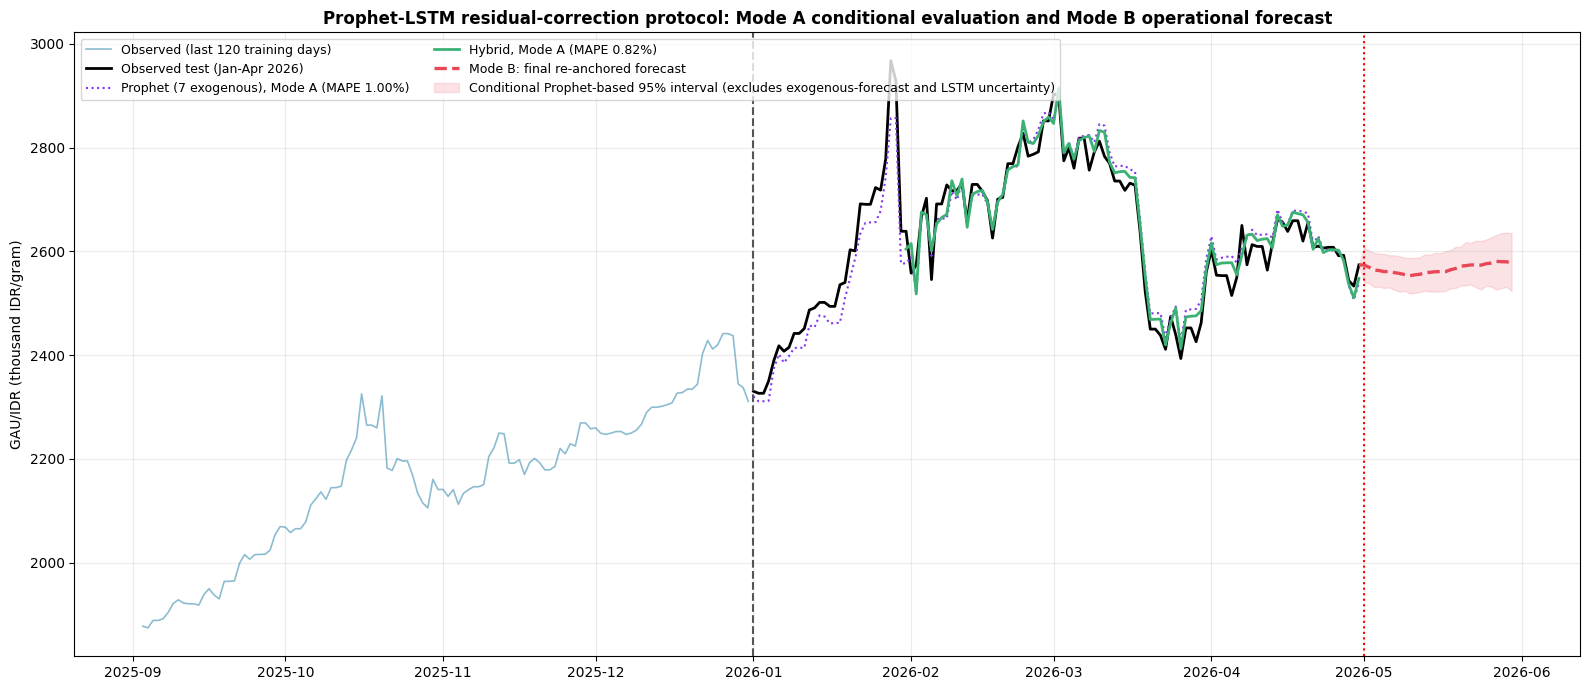

In [ ]:
# Integrated view: history, Mode A predictions, and the Mode B forecast joined at the boundary
fig, ax = plt.subplots(figsize=(16, 7))
hist = y_train.iloc[-120:]
ax.plot(hist.index, np.exp(hist) / 1000, color='#2E86AB', alpha=.55, lw=1.2, label='Observed (last 120 training days)')
ax.plot(X_test.index, y_true_rp_full / 1000, color='black', lw=2, label='Observed test (Jan-Apr 2026)')
ax.plot(X_test.index, y_pred_prophet_rp_full / 1000, color='#8338EC', ls=':', lw=1.5,
        label=f"Prophet (7 exogenous), Mode A (MAPE {metrics_prophet['MAPE (%)']:.2f}%)")
ax.plot(aligned_test_index, y_pred_hybrid_rp / 1000, color='#3BB273', lw=2,
        label=f"Hybrid, Mode A (MAPE {metrics_hybrid['MAPE (%)']:.2f}%)")
cont_dates = pd.Index([pd.Timestamp(FORECAST_ORIGIN)]).append(pd.Index(future_dates))
ax.plot(cont_dates, np.concatenate([[last_observed_rp], final_reanchored_rp]) / 1000, color='#E84855', ls='--', lw=2.4,
        label='Mode B: final re-anchored forecast')
ax.fill_between(cont_dates,
                np.concatenate([[last_observed_rp], operational_forecast['cond_prophet_interval_lower_idr_per_gram']]) / 1000,
                np.concatenate([[last_observed_rp], operational_forecast['cond_prophet_interval_upper_idr_per_gram']]) / 1000,
                color='#E84855', alpha=.15, label='Conditional Prophet-based 95% interval (excludes exogenous-forecast and LSTM uncertainty)')
ax.axvline(pd.Timestamp(TEST_START), color='#555', ls='--'); ax.axvline(future_dates[0], color='red', ls=':')
ax.set_ylabel('GAU/IDR (thousand IDR/gram)'); ax.grid(alpha=.25); ax.legend(loc='upper left', ncol=2, fontsize=9)
ax.xaxis.set_major_locator(mdates.MonthLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax.set_title('Prophet-LSTM residual-correction protocol: Mode A conditional evaluation and Mode B operational forecast', fontweight='bold')
plt.tight_layout(); plt.savefig(OUTPUT_DIR / 'fig_forecast_final.png', dpi=150, bbox_inches='tight'); plt.show()

## **Sub-step 7.3: Benchmark Model Evaluation**


### Stationarity screening and differencing order

In [ ]:
def select_differencing_order(series, name, alpha=ALPHA_ADF, max_diff=MAX_DIFF):
    s, d, rows = series.dropna().copy(), 0, []
    while True:
        res = adfuller(s, autolag='AIC')
        rows.append({'Variable': name, 'd': d, 'ADF statistic': res[0], 'p-value': res[1],
                     'Conclusion': 'stationary' if res[1] < alpha else 'non-stationary'})
        if res[1] < alpha or d >= max_diff:
            return d, rows
        s, d = s.diff().dropna(), d + 1

def apply_differencing(series, d):
    for _ in range(d):
        series = series.diff()
    return series

diff_orders, adf_rows = {}, []
for var in [TARGET] + FEATURES:
    diff_orders[var], rows = select_differencing_order(df_model[var].loc[:TRAIN_END], var)
    adf_rows.extend(rows)
df_adf_report = pd.DataFrame(adf_rows)
display(df_adf_report.style.format({'ADF statistic': '{:.4f}', 'p-value': '{:.6f}'}))
print('Differencing order per series (ADF on training period):', diff_orders)

,Variable,d,ADF statistic,p-value,Conclusion
0,log_GAU_IDR,0,1.9811,0.998648,non-stationary
1,log_GAU_IDR,1,-26.0751,0.000000,stationary
2,log_GAU_USD,0,1.7872,0.998323,non-stationary
3,log_GAU_USD,1,-31.3158,0.000000,stationary
4,DXY,0,-2.1177,0.237465,non-stationary
5,DXY,1,-25.0227,0.000000,stationary
6,FED_Rate,0,-1.8094,0.375827,non-stationary
7,FED_Rate,1,-42.8068,0.000000,stationary
8,BI_Rate,0,-0.9681,0.764734,non-stationary
9,BI_Rate,1,-42.7600,0.000000,stationary


Differencing order per series (ADF on training period): {'log_GAU_IDR': 1, 'log_GAU_USD': 1, 'DXY': 1, 'FED_Rate': 1, 'BI_Rate': 1, 'Inflation': 1, 'log_Oil': 1, 'log_USD_IDR': 1}


### Stand-alone multivariate LSTM: data, scaling and helper functions

In [ ]:
TARGET_MV   = f'{TARGET}__stat'
FEATURES_MV = [f'{f}__stat' for f in FEATURES]
TARGET_D    = diff_orders[TARGET]

df_lstm_mv = pd.DataFrame({f'{v}__stat': apply_differencing(df_model[v], diff_orders[v]) for v in [TARGET] + FEATURES}).dropna()
df_train_mv = df_lstm_mv.loc[:TRAIN_END]
df_test_mv  = df_lstm_mv.loc[TEST_START:TEST_END]
assert df_test_mv.index.equals(X_test.index), 'Stand-alone LSTM test dates must match the main protocol.'

scaler_feat_mv   = MinMaxScaler(feature_range=(-1, 1)).fit(df_train_mv[FEATURES_MV].values)
scaler_target_mv = MinMaxScaler(feature_range=(-1, 1)).fit(df_train_mv[[TARGET_MV]].values)
feat_train_sc   = scaler_feat_mv.transform(df_train_mv[FEATURES_MV].values)
feat_test_sc    = scaler_feat_mv.transform(df_test_mv[FEATURES_MV].values)
target_train_sc = scaler_target_mv.transform(df_train_mv[[TARGET_MV]].values).ravel()
target_test_sc  = scaler_target_mv.transform(df_test_mv[[TARGET_MV]].values).ravel()

def make_sequences_train_mv(window):
    return build_lstm_sequences(feat_train_sc, target_train_sc, window)

def make_sequences_test_mv(window):
    """Prepend the last `window` training rows so every test day gets a prediction."""
    return build_lstm_sequences(np.vstack([feat_train_sc[-window:], feat_test_sc]),
                                np.concatenate([target_train_sc[-window:], target_test_sc]), window)

def reconstruct_target_level(pred_stat, d, level_history, level_actual):
    """Inverse differencing anchored on actual previous levels (one-step-ahead).
    level_history: actual log levels strictly before the first predicted date.
    level_actual : actual log levels on the predicted dates."""
    if d == 0:
        return pred_stat.copy()
    if d == 1:
        return np.concatenate([[level_history[-1]], level_actual[:-1]]) + pred_stat
    if d == 2:
        diff1_last = level_history[-1] - level_history[-2]
        diff1_actual = np.diff(level_actual, prepend=level_history[-1])
        diff1_pred = np.concatenate([[diff1_last], diff1_actual[:-1]]) + pred_stat
        return np.concatenate([[level_history[-1]], level_actual[:-1]]) + diff1_pred
    raise ValueError('Differencing order > 2 is not supported.')

def build_standalone_lstm(window, n_features, units, dropout, lr, l2_reg=STANDALONE_LSTM['l2']):
    model = Sequential([LSTM(units, return_sequences=False, input_shape=(window, n_features), kernel_regularizer=l2(l2_reg)),
                        Dropout(dropout), Dense(1)])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr), loss='mse', metrics=['mae'])
    return model

def chronological_split(X_seq, y_seq, val_frac=STANDALONE_LSTM['val_fraction']):
    n_val = max(1, int(len(X_seq) * val_frac))
    return X_seq[:-n_val], y_seq[:-n_val], X_seq[-n_val:], y_seq[-n_val:], n_val

def train_standalone_lstm(model, X_seq, y_seq, epochs, batch_size, patience, val_frac=STANDALONE_LSTM['val_fraction']):
    X_tr, y_tr, X_val, y_val, _ = chronological_split(X_seq, y_seq, val_frac)
    callbacks = [EarlyStopping(monitor='val_loss', patience=patience, restore_best_weights=True, verbose=0),
                 ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=7, min_lr=1e-6, verbose=0)]
    return model.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=epochs, batch_size=batch_size,
                     callbacks=callbacks, shuffle=False, verbose=0)

print('Stand-alone LSTM frames:', df_train_mv.shape, df_test_mv.shape, '| inputs:', len(FEATURES_MV), 'stationary exogenous variables')

Stand-alone LSTM frames: (1825, 8) (120, 8) | inputs: 7 stationary exogenous variables


### Stand-alone multivariate LSTM: candidate configurations

In [ ]:
def evaluate_standalone_candidate(cfg):
    set_global_seed()
    X_seq, y_seq = make_sequences_train_mv(cfg['window'])
    _, _, X_val, _, n_val = chronological_split(X_seq, y_seq)
    model = build_standalone_lstm(cfg['window'], X_seq.shape[2], cfg['units'], cfg['dropout'], cfg['lr'])
    hist = train_standalone_lstm(model, X_seq, y_seq, STANDALONE_LSTM['tuning_epochs'], cfg['batch'], STANDALONE_LSTM['tuning_patience'])
    pred_stat = scaler_target_mv.inverse_transform(model.predict(X_val, verbose=0)).ravel()
    val_dates = df_train_mv.index[-n_val:]
    level_actual  = y_train.loc[val_dates].values
    level_history = y_train.loc[:val_dates[0]].values[:-1]               # strictly before the first validation date
    pred_level = reconstruct_target_level(pred_stat, TARGET_D, level_history, level_actual)
    mape = float(np.mean(np.abs((np.exp(level_actual) - np.exp(pred_level)) / np.exp(level_actual))) * 100)
    return mape, len(hist.history['loss'])

if RUN_STANDALONE_TUNING:
    tuning_rows = []
    for cfg in STANDALONE_CANDIDATES:
        mape_v, n_ep = evaluate_standalone_candidate(cfg)
        tuning_rows.append({**cfg, 'epochs run': n_ep, 'Validation MAPE (%)': round(mape_v, 4)})
    df_tuning_mv = pd.DataFrame(tuning_rows).sort_values('Validation MAPE (%)').reset_index(drop=True)
    display(df_tuning_mv)
    selected_cfg = df_tuning_mv.iloc[0].to_dict()
else:
    selected_cfg = dict(STANDALONE_CANDIDATES[3])
LSTM_MV_WINDOW, LSTM_MV_UNITS = int(selected_cfg['window']), int(selected_cfg['units'])
LSTM_MV_DROPOUT, LSTM_MV_LR, LSTM_MV_BATCH = float(selected_cfg['dropout']), float(selected_cfg['lr']), int(selected_cfg['batch'])
print(f"Stand-alone LSTM configuration: window={LSTM_MV_WINDOW}, units={LSTM_MV_UNITS}, dropout={LSTM_MV_DROPOUT}, "
      f"lr={LSTM_MV_LR}, batch={LSTM_MV_BATCH}")

,name,window,units,dropout,lr,batch,epochs run,Validation MAPE (%)
0,Short window (20),20,32,0.2,0.0010,16,45,0.6663
1,Large units + small LR,30,64,0.3,0.0005,32,52,0.6688
2,Base (30/32/0.3),30,32,0.3,0.0010,32,61,0.6696
3,Small units + small batch,30,16,0.2,0.0010,16,52,0.6698
4,Long window + high dropout,45,32,0.4,0.0010,32,55,0.6713


Stand-alone LSTM configuration: window=20, units=32, dropout=0.2, lr=0.001, batch=16


### Stand-alone multivariate LSTM: final training and out-of-sample evaluation

Stand-alone LSTM: 50 epochs run | lowest-validation epoch 35 | lowest val_loss 0.044411 | training time 64.0 s


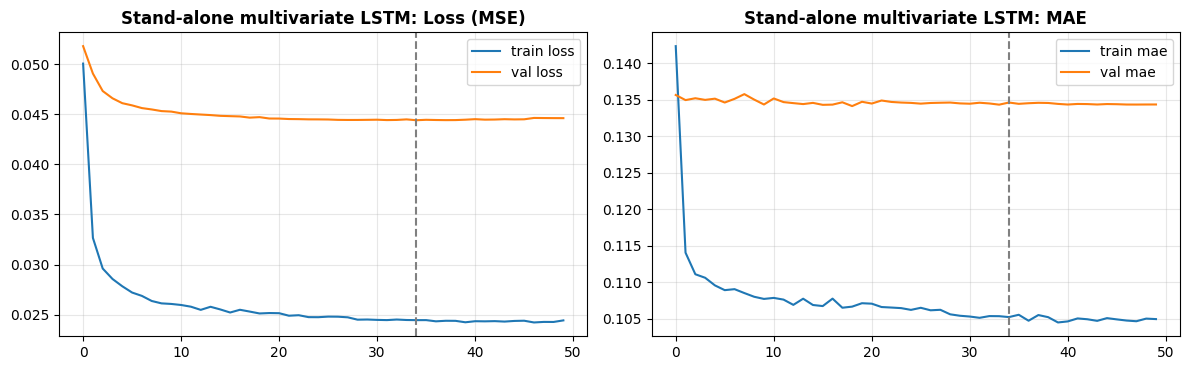

  [Stand-alone multivariate LSTM (benchmark)]  RMSE=Rp49,694  MAE=Rp36,198  MAPE=1.3757%  R²=0.827670


In [ ]:
set_global_seed()
X_train_seq_mv, y_train_seq_mv = make_sequences_train_mv(LSTM_MV_WINDOW)
X_test_seq_mv, _ = make_sequences_test_mv(LSTM_MV_WINDOW)
model_lstm_standalone = build_standalone_lstm(LSTM_MV_WINDOW, X_train_seq_mv.shape[2], LSTM_MV_UNITS, LSTM_MV_DROPOUT, LSTM_MV_LR)

t0 = time.perf_counter()
hist_lstm_standalone = train_standalone_lstm(model_lstm_standalone, X_train_seq_mv, y_train_seq_mv,
                                             STANDALONE_LSTM['max_epochs'], LSTM_MV_BATCH, STANDALONE_LSTM['patience'])
training_time_lstm = time.perf_counter() - t0
best_ep = int(np.argmin(hist_lstm_standalone.history['val_loss']))
print(f"Stand-alone LSTM: {len(hist_lstm_standalone.history['loss'])} epochs run | lowest-validation epoch {best_ep+1} | "
      f"lowest val_loss {min(hist_lstm_standalone.history['val_loss']):.6f} | training time {training_time_lstm:.1f} s")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (m, t) in zip(axes, [('loss', 'Loss (MSE)'), ('mae', 'MAE')]):
    ax.plot(hist_lstm_standalone.history[m], label=f'train {m}'); ax.plot(hist_lstm_standalone.history[f'val_{m}'], label=f'val {m}')
    ax.axvline(best_ep, color='gray', ls='--'); ax.set_title(f'Stand-alone multivariate LSTM: {t}', fontweight='bold'); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

pred_test_stat_mv = scaler_target_mv.inverse_transform(model_lstm_standalone.predict(X_test_seq_mv, verbose=0)).ravel()
y_pred_lstm_log = reconstruct_target_level(pred_test_stat_mv, TARGET_D, y_train.values, y_test.values)
y_pred_lstm_rp_aligned = np.exp(y_pred_lstm_log)[LOOKBACK:]
assert len(y_pred_lstm_rp_aligned) == len(aligned_test_index)
metrics_lstm = compute_metrics(y_true_rp_aligned, y_pred_lstm_rp_aligned, NAME_LSTM)
print_metrics(metrics_lstm)

### Permutation importance (stand-alone LSTM only)

In [ ]:
if RUN_PERMUTATION_IMPORTANCE:
    rng = np.random.default_rng(SEED)
    rows = []
    for j, feat in enumerate(FEATURES):
        Xp = X_test_seq_mv.copy(); Xp[:, :, j] = Xp[rng.permutation(len(Xp)), :, j]
        pred_stat = scaler_target_mv.inverse_transform(model_lstm_standalone.predict(Xp, verbose=0)).ravel()
        pred_rp = np.exp(reconstruct_target_level(pred_stat, TARGET_D, y_train.values, y_test.values))[LOOKBACK:]
        mape_p = np.mean(np.abs((y_true_rp_aligned - pred_rp) / y_true_rp_aligned)) * 100
        rows.append({'Variable': feat, 'MAPE baseline (%)': metrics_lstm['MAPE (%)'], 'MAPE after shuffle (%)': mape_p,
                     'Delta MAPE (pp)': mape_p - metrics_lstm['MAPE (%)']})
    df_perm = pd.DataFrame(rows).sort_values('Delta MAPE (pp)', ascending=False).reset_index(drop=True)
    display(df_perm.style.format({c: '{:.4f}' for c in df_perm.columns if c != 'Variable'}))
    print('Permutation importance applies to the stand-alone LSTM only; the hybrid receives the exogenous variables through Prophet.')

,Variable,MAPE baseline (%),MAPE after shuffle (%),Delta MAPE (pp)
0,DXY,1.3757,1.3807,0.0049
1,BI_Rate,1.3757,1.3777,0.0019
2,log_Oil,1.3757,1.3769,0.0011
3,log_USD_IDR,1.3757,1.3759,0.0002
4,FED_Rate,1.3757,1.3757,-0.0001
5,log_GAU_USD,1.3757,1.3729,-0.0028
6,Inflation,1.3757,1.3683,-0.0074


Permutation importance applies to the stand-alone LSTM only; the hybrid receives the exogenous variables through Prophet.


### Random walk baseline and comparison table

Mode A conditional one-step evaluation | window 2026-01-31 -> 2026-04-30 | N = 90 | lookback 30


,RMSE (Rp),MAE (Rp),MAPE (%),SMAPE (%),R²
Model,,,,,
Random walk,"Rp 49,507","Rp 35,387",1.3437%,1.3423%,0.828961
Prophet (7 exogenous regressors),"Rp 31,819","Rp 26,142",0.9964%,0.9927%,0.929346
Stand-alone multivariate LSTM (benchmark),"Rp 49,694","Rp 36,198",1.3757%,1.3725%,0.827670
Hybrid Prophet-LSTM (residual correction),"Rp 27,546","Rp 21,432",0.8150%,0.8128%,0.947051


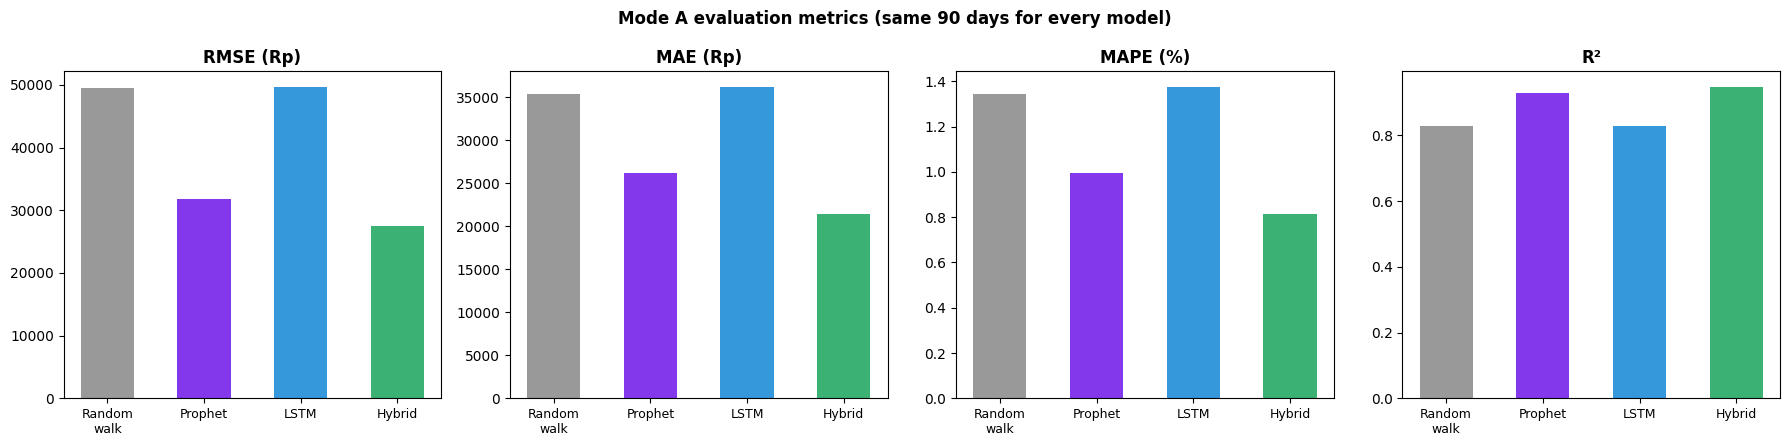

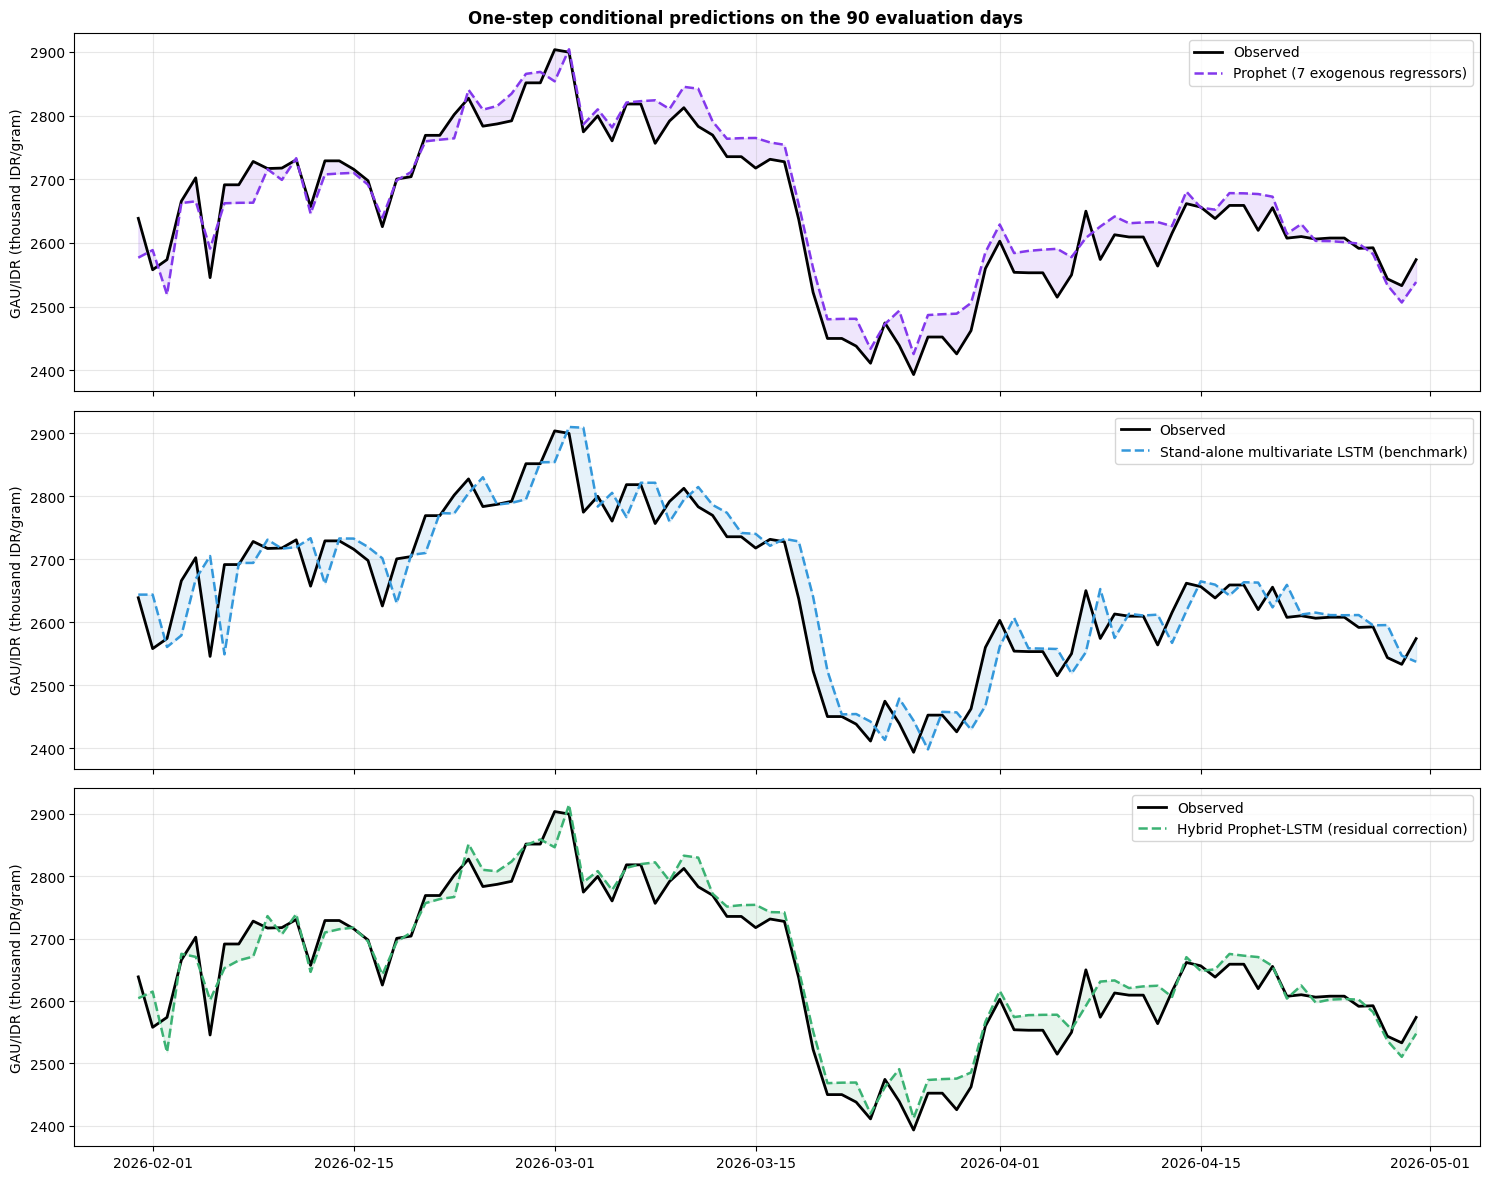

In [ ]:
y_pred_random_walk_rp = np.exp(y_test.values[LOOKBACK - 1:-1])
assert len(y_pred_random_walk_rp) == len(aligned_test_index)
metrics_random_walk = compute_metrics(y_true_rp_aligned, y_pred_random_walk_rp, NAME_RW)

metrics_hybrid['Model']  = NAME_HYBRID
metrics_prophet['Model'] = NAME_PROPHET
metrics_lstm['Model']    = NAME_LSTM
df_eval_full = pd.DataFrame([metrics_random_walk, metrics_prophet, metrics_lstm, metrics_hybrid]).set_index('Model')

print(f'Mode A conditional one-step evaluation | window {aligned_test_index[0].date()} -> {aligned_test_index[-1].date()} | N = {len(aligned_test_index)} | lookback {LOOKBACK}')
display(df_eval_full.style.format({'RMSE (Rp)': 'Rp {:,.0f}', 'MAE (Rp)': 'Rp {:,.0f}', 'MAPE (%)': '{:.4f}%',
                                   'SMAPE (%)': '{:.4f}%', 'R²': '{:.6f}'})
        .set_caption('Out-of-sample conditional one-step-ahead evaluation on the 90 evaluation days (actual contemporaneous exogenous variables and actual preceding values)'))
df_eval_full.to_csv(OUTPUT_DIR / 'protocol_validation_metrics.csv')

model_preds = {NAME_PROPHET: y_pred_prophet_rp_aligned, NAME_LSTM: y_pred_lstm_rp_aligned,
               NAME_HYBRID: y_pred_hybrid_rp}
colors = {NAME_PROPHET: '#8338EC', NAME_LSTM: '#3498DB', NAME_HYBRID: '#3BB273'}

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, metric in zip(axes, ['RMSE (Rp)', 'MAE (Rp)', 'MAPE (%)', 'R²']):
    vals = df_eval_full[metric].values
    ax.bar(range(len(vals)), vals, color=['#999999', '#8338EC', '#3498DB', '#3BB273'], width=.55)
    ax.set_xticks(range(len(vals))); ax.set_xticklabels(['Random\nwalk', 'Prophet', 'LSTM', 'Hybrid'], fontsize=9); ax.set_title(metric, fontweight='bold')
plt.suptitle('Mode A evaluation metrics (same 90 days for every model)', fontweight='bold'); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(3, 1, figsize=(15, 12), sharex=True)
for ax, (name, pred) in zip(axes, model_preds.items()):
    ax.plot(aligned_test_index, y_true_rp_aligned / 1000, color='black', lw=2, label='Observed')
    ax.plot(aligned_test_index, pred / 1000, color=colors[name], ls='--', lw=1.8, label=name)
    ax.fill_between(aligned_test_index, y_true_rp_aligned / 1000, pred / 1000, color=colors[name], alpha=.12)
    ax.set_ylabel('GAU/IDR (thousand IDR/gram)'); ax.legend(); ax.grid(alpha=.3)
plt.suptitle('One-step conditional predictions on the 90 evaluation days', fontweight='bold'); plt.tight_layout(); plt.show()

### Residual diagnostics of the Mode A predictions

,Mean (Rp),Std (Rp),Jarque-Bera p,ADF p (centred),"Ljung-Box p, lag 7","Ljung-Box p, lag 14"
Model,,,,,,
Prophet (7 exogenous regressors),"-12,643","29,200",0.2150,0.7139,4.874e-14,8.56e-19
Stand-alone multivariate LSTM (benchmark),"-4,247","49,512",0.0904,0.1132,0.04885,0.06419
Hybrid Prophet-LSTM (residual correction),"-8,165","26,307",0.4180,0.6383,0.004355,0.0008447


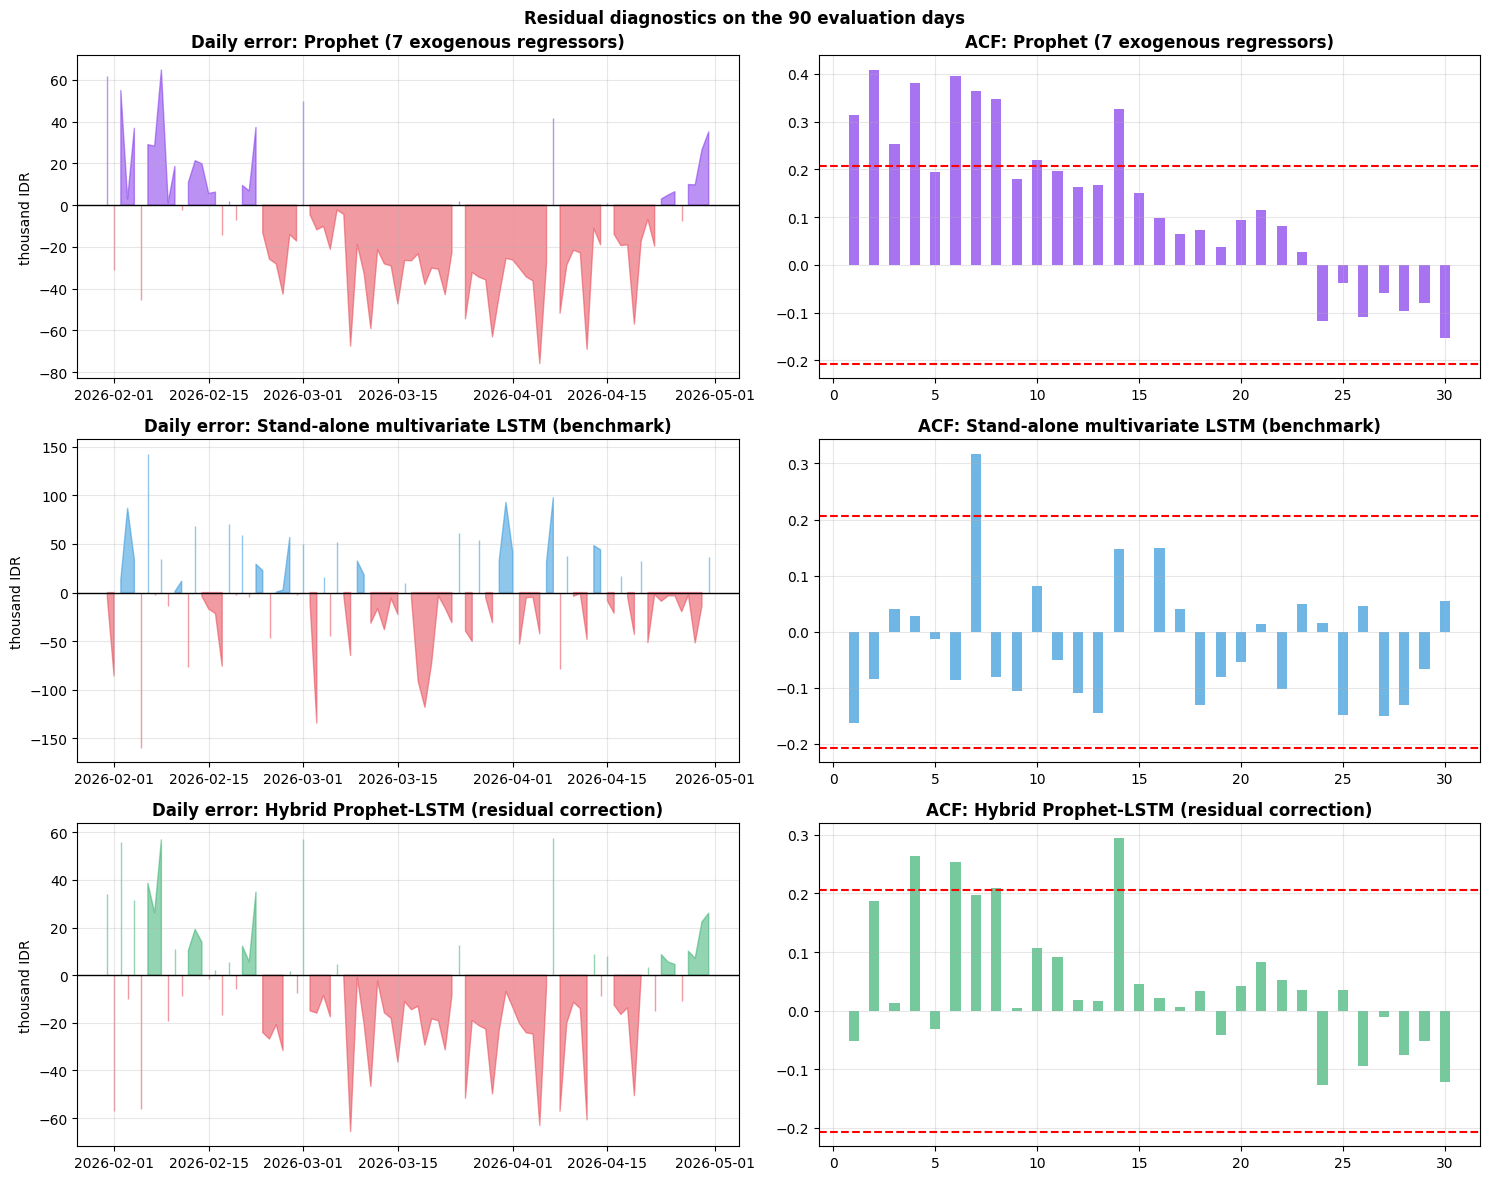

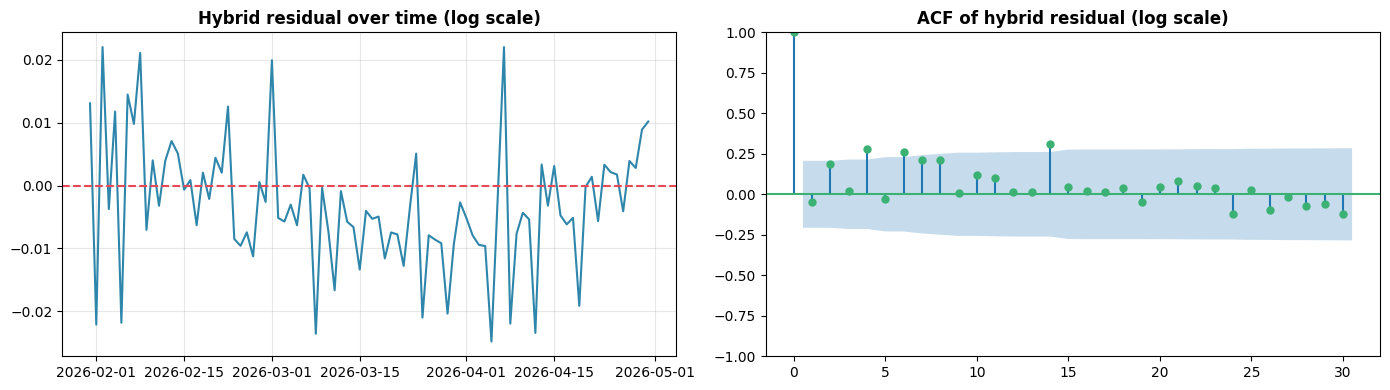

In [ ]:
resid_rp = {NAME_PROPHET: y_true_rp_aligned - y_pred_prophet_rp_aligned,
            NAME_LSTM: y_true_rp_aligned - y_pred_lstm_rp_aligned,
            NAME_HYBRID: y_true_rp_aligned - y_pred_hybrid_rp}

rows = []
for name, r in resid_rp.items():
    lb = acorr_ljungbox(r, lags=[7, 14], return_df=True)
    adf = adfuller(r - r.mean(), autolag='AIC')
    rows.append({'Model': name, 'Mean (Rp)': r.mean(), 'Std (Rp)': r.std(), 'Jarque-Bera p': stats.jarque_bera(r)[1],
                 'ADF p (centred)': adf[1], 'Ljung-Box p, lag 7': lb['lb_pvalue'].iloc[0], 'Ljung-Box p, lag 14': lb['lb_pvalue'].iloc[1]})
df_resid_diag = pd.DataFrame(rows).set_index('Model')
display(df_resid_diag.style.format({'Mean (Rp)': '{:,.0f}', 'Std (Rp)': '{:,.0f}', 'Jarque-Bera p': '{:.4f}', 'ADF p (centred)': '{:.4f}',
                                    'Ljung-Box p, lag 7': '{:.4g}', 'Ljung-Box p, lag 14': '{:.4g}'}))

fig, axes = plt.subplots(3, 2, figsize=(15, 12))
for i, (name, r) in enumerate(resid_rp.items()):
    c = colors[name]
    axes[i, 0].fill_between(aligned_test_index, r / 1000, 0, where=(r >= 0), color=c, alpha=.55)
    axes[i, 0].fill_between(aligned_test_index, r / 1000, 0, where=(r < 0), color='#E84855', alpha=.55)
    axes[i, 0].axhline(0, color='black', lw=1); axes[i, 0].set_title(f'Daily error: {name}', fontweight='bold'); axes[i, 0].set_ylabel('thousand IDR')
    a = acf(r, nlags=30, fft=True); ci = 1.96 / np.sqrt(len(r))
    axes[i, 1].bar(range(1, 31), a[1:], width=.5, color=c, alpha=.7)
    axes[i, 1].axhline(ci, color='red', ls='--'); axes[i, 1].axhline(-ci, color='red', ls='--'); axes[i, 1].set_title(f'ACF: {name}', fontweight='bold')
    axes[i, 0].grid(alpha=.3); axes[i, 1].grid(alpha=.3)
plt.suptitle('Residual diagnostics on the 90 evaluation days', fontweight='bold'); plt.tight_layout(); plt.show()

resid_hybrid_log = y_test.values[LOOKBACK:] - y_pred_hybrid_log
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(aligned_test_index, resid_hybrid_log, color='#2E86AB'); axes[0].axhline(0, color='#E84855', ls='--')
axes[0].set_title('Hybrid residual over time (log scale)', fontweight='bold'); axes[0].grid(alpha=.3)
from statsmodels.graphics.tsaplots import plot_acf
plot_acf(resid_hybrid_log, ax=axes[1], lags=30, alpha=0.05, color='#3BB273'); axes[1].set_title('ACF of hybrid residual (log scale)', fontweight='bold')
plt.tight_layout(); plt.savefig(OUTPUT_DIR / 'fig_residual_diagnostics.png', dpi=200, bbox_inches='tight'); plt.show()

## **Sub-step 7.4: Diebold-Mariano Test**


In [ ]:
def dm_test(y_true, pred1, pred2, h=1, criterion='square'):
    """Diebold-Mariano test on the loss differential d = L(e1) - L(e2). Returns (statistic, p-value, mean_d)."""
    e1, e2 = np.asarray(y_true) - np.asarray(pred1), np.asarray(y_true) - np.asarray(pred2)
    if criterion == 'square':
        d = e1 ** 2 - e2 ** 2
    elif criterion == 'abs':
        d = np.abs(e1) - np.abs(e2)
    else:
        raise ValueError("criterion must be 'square' or 'abs'")
    T, d_bar = len(d), d.mean()
    def autocov(x, k):
        mu = x.mean()
        return np.mean((x - mu) ** 2) if k == 0 else np.mean((x[k:] - mu) * (x[:-k] - mu))
    long_run_var = autocov(d, 0) + 2 * sum(autocov(d, k) for k in range(1, max(0, h - 1) + 1))
    se = np.sqrt(max(long_run_var, 1e-10) / T)
    stat = d_bar / se if se > 1e-10 else (np.inf if d_bar != 0 else 0.0)
    return float(stat), float(2 * (1 - stats.norm.cdf(abs(stat)))), float(d_bar)

dm_models = {NAME_RW: y_pred_random_walk_rp, NAME_PROPHET: y_pred_prophet_rp_aligned,
             NAME_LSTM: y_pred_lstm_rp_aligned, NAME_HYBRID: y_pred_hybrid_rp}
assert all(len(v) == len(y_true_rp_aligned) == MODE_A_N == 90 for v in dm_models.values()), 'DM must use the 90-day Mode A window.'
dm_pairs = [(NAME_RW, NAME_PROPHET), (NAME_RW, NAME_LSTM), (NAME_RW, NAME_HYBRID),
            (NAME_PROPHET, NAME_LSTM), (NAME_PROPHET, NAME_HYBRID), (NAME_LSTM, NAME_HYBRID)]
rows = []
for a, b in dm_pairs:
    stat, p, d_bar = dm_test(y_true_rp_aligned, dm_models[a], dm_models[b], h=1)
    rows.append({'Model 1': a, 'Model 2': b, 'DM statistic': stat, 'p-value': p, 'Significant at 5%': p < 0.05,
                 'Mean squared-error loss': 'Model 1 larger' if d_bar > 0 else 'Model 2 larger'})
df_dm = pd.DataFrame(rows)
print(f'Diebold-Mariano on Mode A (90-day conditional one-step evaluation), h = 1, squared-error loss, T = {len(y_true_rp_aligned)}')
display(df_dm.style.format({'DM statistic': '{:.4f}', 'p-value': '{:.4f}'}))
df_dm.to_csv(OUTPUT_DIR / 'diebold_mariano.csv', index=False)

Diebold-Mariano on Mode A (90-day conditional one-step evaluation), h = 1, squared-error loss, T = 90


,Model 1,Model 2,DM statistic,p-value,Significant at 5%,Mean squared-error loss
0,Random walk,Prophet (7 exogenous regressors),3.0996,0.0019,True,Model 1 larger
1,Random walk,Stand-alone multivariate LSTM (benchmark),-0.4236,0.6719,False,Model 2 larger
2,Random walk,Hybrid Prophet-LSTM (residual correction),3.8867,0.0001,True,Model 1 larger
3,Prophet (7 exogenous regressors),Stand-alone multivariate LSTM (benchmark),-3.0958,0.0020,True,Model 2 larger
4,Prophet (7 exogenous regressors),Hybrid Prophet-LSTM (residual correction),3.8888,0.0001,True,Model 1 larger
5,Stand-alone multivariate LSTM (benchmark),Hybrid Prophet-LSTM (residual correction),3.8693,0.0001,True,Model 1 larger


## **Sub-step 7.5: Data Leakage Audit**


In [ ]:
_ok = {}
_ok['Training data <= 31 Dec 2025'] = bool(X_train.index.max() <= pd.Timestamp(TRAIN_END))
_ok['Main Prophet fitted on observations <= 31 Dec 2025'] = bool(model_prophet.history['ds'].max() <= pd.Timestamp(TRAIN_END))
_ok['Test period = 1 Jan - 30 Apr 2026'] = bool(X_test.index.min() == pd.Timestamp(TEST_START) and X_test.index.max() == pd.Timestamp(TEST_END))
_ok['Train and test do not overlap'] = bool(X_train.index.intersection(X_test.index).empty)
_ok['Mode A: actual contemporaneous exogenous values (allowed, conditional)'] = bool(
    np.allclose(X_test.values, df_model.loc[X_test.index, FEATURES].values) and np.allclose(modeA['prophet_log'], prophet_test_log))
_ok['Scaler fitted on training residuals only'] = bool(
    scaler_res.n_samples_seen_ == len(residual_train) and np.isclose(scaler_res.data_min_[0], residual_train.min())
    and np.isclose(scaler_res.data_max_[0], residual_train.max()))
_ok['Residual LSTM trained on training residual sequences only'] = bool(
    len(X_res_train) == len(X_train) - LOOKBACK and np.allclose(X_res_train[-1, :, 0], residual_train_sc[-LOOKBACK - 1:-1])
    and np.isclose(y_res_train[-1], residual_train_sc[-1]))
_ok['Residual window for day t contains residuals through t-1 only (Mode A)'] = bool(
    np.allclose(modeA['residual_test'], residual_test_full)
    and all(np.allclose(X_res_test[k, :, 0], residual_combined_sc[k:k + LOOKBACK]) for k in range(len(X_res_test)))
    and np.allclose(X_res_test[1:, -1, 0], y_res_test[:-1]))
_ok['Exogenous forecast models: data up to origin only'] = bool(df_all.index.max() <= pd.Timestamp(FORECAST_ORIGIN))
_ok['Mode B: all 7 exogenous variables forecast, 30 rows, no NaN'] = bool(
    future_exog.shape[0] == HORIZON and len(FUTURE_EXOG_COLUMNS) == 7 and set(FUTURE_EXOG_COLUMNS) <= set(future_exog.columns)
    and not future_exog.isna().any().any() and not future_regressors.isna().any().any())
_ok['Mode B: forecast dates = 1 - 30 May 2026'] = bool(
    future_dates[0] == pd.Timestamp(FORECAST_START) and future_dates[-1] == pd.Timestamp(FORECAST_END) and future_dates.intersection(df_all.index).empty)

# Identity test: a forecast that is numerically identical to an actual post-origin value would indicate leakage.
_identical, _n_checked = [], 0
for s in EXOG_SPEC:
    fut_actual = series_raw[s['name']].loc[future_dates[0]:future_dates[-1]].dropna()
    if len(fut_actual):
        _n_checked += 1
        fc_vals = future_exog.set_index('ds')[s['name']].reindex(fut_actual.index).to_numpy()
        _identical.append(bool(np.allclose(fc_vals, fut_actual.to_numpy(), rtol=1e-9, atol=0)))
_ok['Mode B: no actual May 2026 exogenous values in the forecast matrix'] = not any(_identical)
_ok['Mode B: no actual target value in the future matrices'] = bool('GAU_IDR' not in future_exog.columns and TARGET not in future_regressors.columns)
_ok['Mode B: initial residual window = observed residuals through 30 Apr 2026'] = bool(
    initial_window_dates[-1] == pd.Timestamp(FORECAST_ORIGIN)
    and np.allclose(residual_window_at_origin_sc, scale_residuals(scaler_res, residual_test_full[-LOOKBACK:])))
_ok['Mode B: after step 1 the residual window holds predicted residuals only'] = bool(
    np.allclose(modeB['input_windows'][0], residual_window_at_origin_sc)
    and all(np.allclose(modeB['input_windows'][h][LOOKBACK - h:], modeB['predicted_residual_sc'][:h]) for h in range(min(HORIZON, LOOKBACK)))
    and all(np.allclose(modeB['input_windows'][h][:LOOKBACK - h], residual_window_at_origin_sc[h:]) for h in range(min(HORIZON, LOOKBACK))))
_ok['Re-anchoring: delta uses only the last observed value and the raw day-1 forecast'] = bool(
    np.isclose(last_observed_log, np.log(df_all.loc[FORECAST_ORIGIN, 'GAU_IDR'])) and np.isclose(delta, last_observed_log - raw_hybrid_log[0]))
_ok['DM test uses the 90-day Mode A window only'] = bool(all(len(v) == MODE_A_N for v in dm_models.values()))

leakage_audit = pd.DataFrame({'check': list(_ok), 'passed': ['PASS' if v else 'FAIL' for v in _ok.values()]})
display(leakage_audit)
print(f'Identity test against post-origin actuals: {_n_checked} exogenous series have actual values after the origin in the raw files '
      f'({"none identical to the forecasts" if not any(_identical) else "IDENTICAL FOUND"}).')
assert all(_ok.values()), 'Data leakage audit failed.'
leakage_ok = _ok

,check,passed
0,Training data <= 31 Dec 2025,PASS
1,Main Prophet fitted on observations <= 31 Dec ...,PASS
2,Test period = 1 Jan - 30 Apr 2026,PASS
3,Train and test do not overlap,PASS
4,Mode A: actual contemporaneous exogenous value...,PASS
5,Scaler fitted on training residuals only,PASS
6,Residual LSTM trained on training residual seq...,PASS
7,Residual window for day t contains residuals t...,PASS
8,Exogenous forecast models: data up to origin only,PASS
9,"Mode B: all 7 exogenous variables forecast, 30...",PASS


Identity test against post-origin actuals: 4 exogenous series have actual values after the origin in the raw files (none identical to the forecasts).


## **Sub-step 7.6: Numerical Consistency Audit**


In [ ]:
MANUSCRIPT_REFERENCE = {
    'mode_a': {NAME_PROPHET: dict(rmse_k=31.819, mape=0.9964),
               NAME_LSTM:    dict(rmse_k=49.712, mape=1.3739),
               NAME_HYBRID:  dict(rmse_k=27.448, mape=0.8096)},
    'dm': {(NAME_PROPHET, NAME_LSTM):   (-3.1048, 0.0019),
           (NAME_PROPHET, NAME_HYBRID): ( 3.8839, 0.0001),
           (NAME_LSTM,    NAME_HYBRID): ( 3.8955, 0.0001)},
}

def _status(actual, ref, decimals):
    return 'match' if abs(actual - ref) <= 0.5 * 10 ** (-decimals) + 1e-12 else 'differs'

audit_rows = []
for name, ref in MANUSCRIPT_REFERENCE['mode_a'].items():
    m = df_eval_full.loc[name]
    rmse_k = float(m['RMSE (Rp)']) / 1000.0
    audit_rows.append({'Item': f'{name} | RMSE (thousand Rp)', 'Manuscript': ref['rmse_k'], 'Notebook': rmse_k,
                       'Difference': rmse_k - ref['rmse_k'], 'Status': _status(rmse_k, ref['rmse_k'], 3)})
    audit_rows.append({'Item': f'{name} | MAPE (%)', 'Manuscript': ref['mape'], 'Notebook': float(m['MAPE (%)']),
                       'Difference': float(m['MAPE (%)']) - ref['mape'], 'Status': _status(float(m['MAPE (%)']), ref['mape'], 4)})
for (a, b), (ref_stat, ref_p) in MANUSCRIPT_REFERENCE['dm'].items():
    r = df_dm[(df_dm['Model 1'] == a) & (df_dm['Model 2'] == b)].iloc[0]
    audit_rows.append({'Item': f'DM statistic | {a} vs {b}', 'Manuscript': ref_stat, 'Notebook': float(r['DM statistic']),
                       'Difference': float(r['DM statistic']) - ref_stat, 'Status': _status(float(r['DM statistic']), ref_stat, 4)})
    audit_rows.append({'Item': f'DM p-value | {a} vs {b}', 'Manuscript': ref_p, 'Notebook': float(r['p-value']),
                       'Difference': float(r['p-value']) - ref_p, 'Status': _status(float(r['p-value']), ref_p, 4)})
audit_rows.append({'Item': 'Number of Mode A evaluation days', 'Manuscript': 90, 'Notebook': len(aligned_test_index),
                   'Difference': len(aligned_test_index) - 90, 'Status': 'match' if len(aligned_test_index) == 90 else 'differs'})

numeric_audit = pd.DataFrame(audit_rows)
display(numeric_audit.style.format({'Manuscript': '{:.4f}', 'Notebook': '{:.4f}', 'Difference': '{:+.4f}'}))
print('Full-scale RMSE (Rp/gram):', {n: round(float(df_eval_full.loc[n, 'RMSE (Rp)']), 1) for n in MANUSCRIPT_REFERENCE['mode_a']})

numeric_audit_all_match = bool((numeric_audit['Status'] == 'match').all())
if numeric_audit_all_match:
    print('Numerical audit: ALL values match the manuscript at the reported precision.')
else:
    print('Numerical audit: some values differ. Values above are the ACTUAL notebook output; nothing was overwritten.')
    print('Check, in this order: (1) random seed, (2) train/test split, (3) residual scaler, (4) residual construction,')
    print('(5) lookback, (6) Mode A evaluation window, (7) model configuration, (8) actual vs forecasted exogenous inputs in Mode A,')
    print('(9) accidental retraining, (10) library versions (see Sub-step 7.8). Items 1-7 are verified programmatically in Sub-steps 7.5 and 7.7.')

,Item,Manuscript,Notebook,Difference,Status
0,Prophet (7 exogenous regressors) | RMSE (thousand Rp),31.8190,31.8193,+0.0003,match
1,Prophet (7 exogenous regressors) | MAPE (%),0.9964,0.9964,+0.0000,match
2,Stand-alone multivariate LSTM (benchmark) | RMSE (thousand Rp),49.7120,49.6939,-0.0181,differs
3,Stand-alone multivariate LSTM (benchmark) | MAPE (%),1.3739,1.3757,+0.0018,differs
4,Hybrid Prophet-LSTM (residual correction) | RMSE (thousand Rp),27.4480,27.5456,+0.0976,differs
5,Hybrid Prophet-LSTM (residual correction) | MAPE (%),0.8096,0.8150,+0.0054,differs
6,DM statistic | Prophet (7 exogenous regressors) vs Stand-alone multivariate LSTM (benchmark),-3.1048,-3.0958,+0.0090,differs
7,DM p-value | Prophet (7 exogenous regressors) vs Stand-alone multivariate LSTM (benchmark),0.0019,0.0020,+0.0001,differs
8,DM statistic | Prophet (7 exogenous regressors) vs Hybrid Prophet-LSTM (residual correction),3.8839,3.8888,+0.0049,differs
9,DM p-value | Prophet (7 exogenous regressors) vs Hybrid Prophet-LSTM (residual correction),0.0001,0.0001,+0.0000,match


Full-scale RMSE (Rp/gram): {'Prophet (7 exogenous regressors)': 31819.3, 'Stand-alone multivariate LSTM (benchmark)': 49693.9, 'Hybrid Prophet-LSTM (residual correction)': 27545.6}
Numerical audit: some values differ. Values above are the ACTUAL notebook output; nothing was overwritten.
Check, in this order: (1) random seed, (2) train/test split, (3) residual scaler, (4) residual construction,
(5) lookback, (6) Mode A evaluation window, (7) model configuration, (8) actual vs forecasted exogenous inputs in Mode A,
(9) accidental retraining, (10) library versions (see Sub-step 7.8). Items 1-7 are verified programmatically in Sub-steps 7.5 and 7.7.


## **Sub-step 7.7: Reproducibility Audit**

In [ ]:
_spec = [
    ('Random seed', SEED, 42), ('Lookback', LOOKBACK, 30), ('Lambda', LAMBDA, 0.5), ('Forecast horizon (days)', HORIZON, 30),
    ('Forecast origin', FORECAST_ORIGIN, '2026-04-30'), ('Training end', TRAIN_END, '2025-12-31'),
    ('Test start', TEST_START, '2026-01-01'), ('Test end', TEST_END, '2026-04-30'),
    ('Mode A window', f'{MODE_A_START} to {MODE_A_END} ({MODE_A_N} days)', '2026-01-31 to 2026-04-30 (90 days)'),
    ('Number of Prophet exogenous regressors', len(FEATURES), 7),
    ('Residual scaler range', RESIDUAL_SCALER_RANGE, (-1, 1)),
    ('Residual LSTM units', RESIDUAL_LSTM['units'], 16), ('Residual LSTM dropout', RESIDUAL_LSTM['dropout'], 0.4),
    ('Residual LSTM L2', RESIDUAL_LSTM['l2'], 0.01), ('Optimizer', RESIDUAL_LSTM['optimizer'], 'adam'),
    ('Learning rate', RESIDUAL_LSTM['learning_rate'], 0.001), ('Loss', RESIDUAL_LSTM['loss'], 'mse'),
    ('Batch size', RESIDUAL_LSTM['batch_size'], 32), ('Maximum epochs', RESIDUAL_LSTM['max_epochs'], 80),
    ('EarlyStopping patience', RESIDUAL_LSTM['patience'], 10), ('Validation fraction (last 10% of sequences)', RESIDUAL_LSTM['val_fraction'], 0.10),
    ('shuffle', RESIDUAL_LSTM['shuffle'], False),
    ('Prophet changepoint_prior_scale', PROPHET_MAIN['changepoint_prior_scale'], 0.10),
    ('Prophet seasonality_prior_scale', PROPHET_MAIN['seasonality_prior_scale'], 5.0),
    ('Prophet interval_width', PROPHET_MAIN['interval_width'], 0.95),
]
repro_audit = pd.DataFrame([(k, str(a), str(e), 'PASS' if a == e else 'FAIL') for k, a, e in _spec],
                           columns=['parameter', 'configured', 'protocol', 'status'])
display(repro_audit)
print('Environment: PYTHONHASHSEED =', os.environ.get('PYTHONHASHSEED'), '| TF_DETERMINISTIC_OPS =', os.environ.get('TF_DETERMINISTIC_OPS'))
assert (repro_audit['status'] == 'PASS').all(), 'Configured parameters deviate from the protocol specification.'

,parameter,configured,protocol,status
0,Random seed,42,42,PASS
1,Lookback,30,30,PASS
2,Lambda,0.5,0.5,PASS
3,Forecast horizon (days),30,30,PASS
4,Forecast origin,2026-04-30,2026-04-30,PASS
5,Training end,2025-12-31,2025-12-31,PASS
6,Test start,2026-01-01,2026-01-01,PASS
7,Test end,2026-04-30,2026-04-30,PASS
8,Mode A window,2026-01-31 to 2026-04-30 (90 days),2026-01-31 to 2026-04-30 (90 days),PASS
9,Number of Prophet exogenous regressors,7,7,PASS


Environment: PYTHONHASHSEED = 42 | TF_DETERMINISTIC_OPS = 1


## **Sub-step 7.8: Environment and Parameter Summary**


In [ ]:
import platform, sys, importlib.metadata as md_
def _v(pkg):
    try: return md_.version(pkg)
    except Exception: return 'n/a'

summary_rows = [
    ('Dataset', 'GAU/IDR example dataset; target + 7 exogenous variables'),
    ('Period', f'{DATA_START} to {FORECAST_ORIGIN} (daily calendar)'),
    ('Training / test', f'{DATA_START} to {TRAIN_END} / {TEST_START} to {TEST_END}'),
    ('Data cutoff', f'training end {TRAIN_END}; forecast origin {FORECAST_ORIGIN}'),
    ('Forecast horizon / residual lookback', f'{HORIZON} days / {LOOKBACK} days'),
    ('Mode A (conditional one-step-ahead) evaluation window', f'{aligned_test_index[0].date()} to {aligned_test_index[-1].date()} ({len(aligned_test_index)} days)'),
    ('Mode B (operational recursive) forecast', f'{future_dates[0].date()} to {future_dates[-1].date()} ({HORIZON} days), origin {FORECAST_ORIGIN}'),
    ('Target transformation', 'natural logarithm'),
    ('Prophet with seven exogenous regressors', f'{len(FEATURES)}: ' + ', '.join(FEATURES)),
    ('Prophet main parameters', str(PROPHET_MAIN)),
    ('Exogenous Prophet models', f"{EXOG_PROPHET_COMMON}; changepoint_prior_scale 0.20 (market) / 0.03 (macro)"),
    ('Residual LSTM (univariate)', f"{RESIDUAL_LSTM}; lookback {LOOKBACK}; input = 30-day Prophet residual sequence only"),
    ('Residual scaler', f'MinMaxScaler(feature_range={RESIDUAL_SCALER_RANGE}), fitted on training residuals only'),
    ('Lambda', LAMBDA),
    ('Re-anchoring', 'one constant log-scale delta = y_T - raw forecast(T+1), applied to all 30 steps'),
    ('Stand-alone multivariate LSTM', 'benchmark only; not part of the Prophet-LSTM residual-correction protocol'),
    ('Seed', f'{SEED} (Python, NumPy, TensorFlow; NumPy reseeded before every Prophet predict call)'),
    ('Determinism', 'TF_DETERMINISTIC_OPS=1, PYTHONHASHSEED=42'),
    ('Software', f"Python {platform.python_version()}, prophet {_v('prophet')}, tensorflow {tf.__version__}, pandas {pd.__version__}, "
                 f"numpy {np.__version__}, scikit-learn {_v('scikit-learn')}, statsmodels {_v('statsmodels')}, scipy {_v('scipy')}"),
    ('Files written', ', '.join(sorted(p.name for p in OUTPUT_DIR.iterdir()))),
]
display(pd.DataFrame(summary_rows, columns=['Item', 'Value']).style.hide(axis='index').set_properties(**{'text-align': 'left'}))

Item,Value
Dataset,GAU/IDR example dataset; target + 7 exogenous variables
Period,2021-01-01 to 2026-04-30 (daily calendar)
Training / test,2021-01-01 to 2025-12-31 / 2026-01-01 to 2026-04-30
Data cutoff,training end 2025-12-31; forecast origin 2026-04-30
Forecast horizon / residual lookback,30 days / 30 days
Mode A (conditional one-step-ahead) evaluation window,2026-01-31 to 2026-04-30 (90 days)
Mode B (operational recursive) forecast,"2026-05-01 to 2026-05-30 (30 days), origin 2026-04-30"
Target transformation,natural logarithm
Prophet with seven exogenous regressors,"7: log_GAU_USD, DXY, FED_Rate, BI_Rate, Inflation, log_Oil, log_USD_IDR"
Prophet main parameters,"{'growth': 'linear', 'n_changepoints': 25, 'changepoint_range': 0.8, 'seasonality_mode': 'additive', 'changepoint_prior_scale': 0.1, 'seasonality_prior_scale': 5.0, 'yearly_seasonality': True, 'weekly_seasonality': True, 'daily_seasonality': False, 'interval_width': 0.95, 'mcmc_samples': 0, 'uncertainty_samples': 1000}"


## **Sub-step 7.9: Final Quality Control**

In [ ]:
qc = [
    ('1. Prophet uses exactly 7 exogenous regressors', len(model_prophet.extra_regressors) == 7 and sorted(model_prophet.extra_regressors) == sorted(FEATURES), True),
    ('2. Residual LSTM remains univariate', model_residual_lstm.input_shape == (None, LOOKBACK, 1), True),
    ('3. Residual LSTM uses residuals through t-1 only', leakage_ok['Residual window for day t contains residuals through t-1 only (Mode A)'], True),
    ('4. Mode A uses actual contemporaneous exogenous variables', leakage_ok['Mode A: actual contemporaneous exogenous values (allowed, conditional)'], True),
    ('5. Mode B forecasts all 7 exogenous variables first', exog_forecast_model_space.shape == (HORIZON, 7) and leakage_ok['Mode B: all 7 exogenous variables forecast, 30 rows, no NaN'], True),
    ('6. Mode B uses no actual May 2026 values', leakage_ok['Mode B: no actual May 2026 exogenous values in the forecast matrix'] and leakage_ok['Mode B: no actual target value in the future matrices'], True),
    ('7. After step 1 the residual window holds predicted residuals only', leakage_ok['Mode B: after step 1 the residual window holds predicted residuals only'], True),
    ('8. delta computed from last observed value and raw first forecast', bool(np.isclose(delta, last_observed_log - raw_hybrid_log[0])), True),
    ('9. delta is constant over the 30 days', bool(np.allclose(final_reanchored_log - raw_hybrid_log, delta)) and len(final_reanchored_log) == 30, True),
    ('10. DM test uses only the 90-day conditional evaluation', leakage_ok['DM test uses the 90-day Mode A window only'], True),
    ('11. Numerical outputs consistent with the manuscript (reported, see Sub-step 7.6)', numeric_audit_all_match, False),
    ('12. Dataset validation passed (calendar, ordering, columns, numeric types, missing values)', bool(structural_report['passed'].all()), True),
    ('13. Log transformation applied to GAU/IDR, GAU/USD, crude oil and USD/IDR only', set(LOG_VARIABLES) == {'GAU_IDR', 'GAU_USD', 'Oil', 'USD_IDR'}, True),
    ('14. Training, test and forecast-origin dates match the configuration', leakage_ok['Training data <= 31 Dec 2025'] and leakage_ok['Test period = 1 Jan - 30 Apr 2026'] and leakage_ok['Mode B: forecast dates = 1 - 30 May 2026'], True),
    ('15. Output dimensions: 30-row operational forecast and 30 x 7 future exogenous matrix', len(operational_forecast) == HORIZON and exog_forecast_model_space.shape == (HORIZON, 7), True),
    ('16. Boundary-continuity validation passed', all(continuity_checks.values()), True),
    ('17. Reproducibility audit: every configured parameter equals the protocol value', bool((repro_audit['status'] == 'PASS').all()), True),
    ('18. Notebook executed up to this cell without error (cell reached)', True, True),
]
qc_table = pd.DataFrame([(n, 'PASS' if bool(ok) else 'FAIL', 'stops run' if hard else 'reported only') for n, ok, hard in qc],
                        columns=['check', 'result', 'behaviour on failure'])
display(qc_table)
assert all(bool(ok) for _, ok, hard in qc if hard), 'Final quality control failed.'
print(f"{int(sum(bool(ok) for _, ok, _ in qc))}/{len(qc)} final quality-control checks passed.")

,check,result,behaviour on failure
0,1. Prophet uses exactly 7 exogenous regressors,PASS,stops run
1,2. Residual LSTM remains univariate,PASS,stops run
2,3. Residual LSTM uses residuals through t-1 only,PASS,stops run
3,4. Mode A uses actual contemporaneous exogenou...,PASS,stops run
4,5. Mode B forecasts all 7 exogenous variables ...,PASS,stops run
5,6. Mode B uses no actual May 2026 values,PASS,stops run
6,7. After step 1 the residual window holds pred...,PASS,stops run
7,8. delta computed from last observed value and...,PASS,stops run
8,9. delta is constant over the 30 days,PASS,stops run
9,10. DM test uses only the 90-day conditional e...,PASS,stops run


17/18 final quality-control checks passed.
